In [2]:
import os, re, sys, importlib, glob
import re
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
from plotnine import *
from geopy.distance import geodesic, great_circle
from scipy.stats import ttest_ind
import baltic as bt
from scipy.special import binom
from collections import defaultdict, Counter
import arviz as az

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html


In [3]:
# This script prodives code to analyze and plot Markov jumps and rewards for host and flyway data
# Plots: host source/sink markov jumps, host markov jumps over time, overall host markov rewards, flyway source/sink markov jumps, flyway markov jumps over time, host markov rewards per week
# Input: posterior distribution of trees with host and flyway markov jumps, MCC tree with markov jumps for rewards over time, combined log file

In [4]:
def get_season(y):

    y_r = round(y, 5)
    
    if y_r <= 2021.96986: # late autumn 2021
        return "autumn_2021"
    elif 2021.96986 < y_r <= 2022.21096: # winter 2021-22
        return "winter_2021/22"
    elif 2022.21096 < y_r <= 2022.46575: # spring 2022
        return "spring_2022"
    elif 2022.46575 < y_r <= 2022.72055: # summer 2022
        return "summer_2022"
    elif 2022.72055 < y_r <= 2022.96712: # autumn 2022
        return "autumn_2022"
    elif 2022.96712 < y_r <= 2023.21096: # winter 2022-23
        return "winter_2022/23"
    elif 2023.21096 < y_r <= 2023.46575: # spring 2023
        return "spring_2023"
    elif 2023.46575 < y_r <= 2023.72329: # summer 2023
        return "summer_2023"
    elif 2023.72329 < y_r <= 2023.96712: # autumn 2023
        return "autumn_2023"
    elif 2023.96712 < y_r <= 2024.21038: # winter 2023-24
        return "winter_2023/24"
    elif 2024.21038 < y_r <= 2024.46448: # spring 2024
        return "spring_2024"
    elif 2024.46448 < y_r <= 2024.72131: # summer 2024
        return "summer_2024"
    elif 2024.72131 < y_r <= 2024.96721: # autumn 2024
        return "autumn_2024"
    elif y_r > 2024.96721: # winter 2024
        return "winter_2024"
    else:
        return "unknown"

In [5]:
def get_month(y):

    y_r = round(y, 5)
    
    if 2021.665753 <= y_r < 2021.747945: 
        return "september"
    elif 2021.747945 <= y_r < 2021.832877: 
        return "october"
    elif 2021.832877 <= y_r < 2021.915068: 
        return "november"
    elif 2021.915068 <= y_r < 2022.000000: 
        return "december"
    elif 2022.000000 <= y_r < 2022.084932: 
        return "january"
    elif 2022.084932 <= y_r < 2022.161644:
        return "february"
    elif 2022.161644 <= y_r < 2022.246575:
        return "march"
    elif 2022.246575 <= y_r < 2022.328767:
        return "april"
    elif 2022.328767 <= y_r < 2022.413699:
        return "may"
    elif 2022.413699 <= y_r < 2022.495890:
        return "june"
    elif 2022.495890 <= y_r < 2022.580822:
        return "july"
    elif 2022.580822 <= y_r < 2022.665753:
        return "august"
    elif 2022.665753 <= y_r < 2022.747945:
        return "september"
    elif 2022.747945 <= y_r < 2022.832877: 
        return "october"
    elif 2022.832877 <= y_r < 2022.915068:
        return "november"
    elif 2022.915068 <= y_r < 2023.000000:
        return "december"
    elif 2023.000000 <= y_r < 2023.084932:
        return "january"
    elif 2023.084932 <= y_r < 2023.161644:
        return "february"
    elif 2023.161644 <= y_r < 2023.246575:
        return "march"
    elif 2023.246575 <= y_r < 2023.328767:
        return "april"
    elif 2023.328767 <= y_r < 2023.413699:
        return "may"
    elif 2023.413699 <= y_r < 2023.495890:
        return "june"
    elif 2023.495890 <= y_r < 2023.580822:
        return "july"
    elif 2023.580822 <= y_r < 2023.665753:
        return "august"
    elif 2023.665753 <= y_r < 2023.747945:
        return "september"
    elif 2023.747945 <= y_r < 2023.832877:
        return "october"
    elif 2023.832877 <= y_r < 2023.915068:
        return "november"
    elif 2023.915068 <= y_r < 2024.000000:
        return "december"
    elif 2024.000000 <= y_r < 2024.084699:
        return "january"
    elif 2024.084699 <= y_r < 2024.163934:
        return "february"
    elif 2024.163934 <= y_r < 2024.248634:
        return "march"
    elif 2024.248634 <= y_r < 2024.330601:
        return "april"
    elif 2024.330601 <= y_r < 2024.415301:
        return "may"
    elif 2024.415301 <= y_r < 2024.497268:
        return "june"
    elif 2024.497268 <= y_r < 2024.581967:
        return "july"
    elif 2024.581967 <= y_r < 2024.666667:
        return "august"
    elif 2024.666667 <= y_r < 2024.748634:
        return "september"
    elif 2024.748634 <= y_r < 2024.833333:
        return "october"
    elif 2024.833333 <= y_r < 2024.915301:
        return "november"
    elif y_r >= 2024.915301:
        return "december"
    else:
        return "unknown"

In [6]:
host_colors = {"bird-of-prey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "goose-swan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbird-etc":"#D9A7B0", # pink
                     "ground-bird":"#E08907", # orange
                     "diving-bird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }

host_labels = {"bird-of-prey":"Birds of Prey", # red-maroon
                     "duck":"Ducks", # green 
                     "goose-swan": "Geese and Swans", # yellow
                     "shorebird":"Shorebirds and Seabirds", # blue
                     "songbird-etc":"Songbirds, Corvids, etc.", # pink
                     "ground-bird":"Ground Birds", # orange
                     "diving-bird":"Diving Birds", # deep purple
                     "other":"Other" # grey
                    }

flyway_colors = {"AtlanticFlyway":"#AA7722", "PacificFlyway":"#2B57B3", "CentralFlyway":"#5E9B82", "MississippiFlyway":"#C593D1"}

flyway_labels = {"AtlanticFlyway":"Atlantic", "PacificFlyway":"Pacific", "CentralFlyway":"Central", "MississippiFlyway":"Mississippi"}

In [170]:
# This code from Qiqi extracts the date, origin, and destination of each markov jump
# With a couple additions from me (noted by comments)
# Repository DOI: 10.5281/zenodo.10480799

def extractJumpTrees(filedir, mrsd, burnin,outputFiledir):
    k=0
    jumplist=[]

    with open(filedir) as jumpTrees:
        # if the input file has the whole information from BEAST, i.e. other tree information at the start, then 
        # the following codes are activated:
        for line in jumpTrees:
            if line.startswith('tree STATE_'):
                break
                
        for line in jumpTrees:
            if line.startswith('End'):
                break
                set_trace()
                
            k+=1
            state = re.search(r"\d+(?=\s)",line).group(0)
            # jumps = re.findall(r"\{(\d+\.\d+\,\w+\,\w+)\}",line)
            jumps = re.findall(r"\{(\d+\.\d+,\s*[\w-]+,\s*[\w-]+)\}", line) # I updated this line to get the correct REGEX
            jumphistory = [re.split(",",jump,3) for jump in jumps]
            # print(jumphistory)
            df = pd.DataFrame(jumphistory,columns=['height','origin','destination'])
            df['treeNumber'] = k
            df['date'] = mrsd
            df['date'] = df['date']- [float(x) for x in df['height']]
            df['year'] = df['date'].astype(str).str.split(".", expand = True)[0] # I added year because I want to calculate the number of Markov jumps per year
            jumplist.extend([df])
            
            if line.endswith(';'):
                continue
            
    allTreesJumps = pd.concat(jumplist,axis=0)
    maxTreeNum = allTreesJumps.max()['treeNumber']
    allTreesJumps_bi = allTreesJumps[allTreesJumps['treeNumber'] > int(burnin*maxTreeNum)]
    allTreesJumps_bi.to_csv(outputFiledir, sep = "\t")

    return(allTreesJumps_bi)

In [171]:
HOSTTREES = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_liveharvest_ha_traits_mjr/main-intro_liveharvest_ha_traits_901combined.host.history.trees"
FLYWAYTREES = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_liveharvest_ha_traits_mjr/main-intro_liveharvest_ha_traits_combined.flyway.history.trees"


MRSD = 2025.0438356164384 # Most recent sampling date

# eq-time-host-1000 - 2024.8989071038252
# eq-time-host-3000 - 2024.8989071038252
# prop-time-loc - 2024.9453551912568
# prop-time-host - 2024.9453551912568
# liveharvest - 2025.0438356164384
# Eq-time-loc - 2025.054794520548

JUMPSOUTPUT1 = "./analyses/main-intro_six-datasets_mjr/live-harvest/main-intro_liveharvest_ha_host-jumps.tsv"
JUMPSOUTPUT2 = "./analyses/main-intro_six-datasets_mjr/live-harvest/main-intro_liveharvest_ha_flyway-jumps.tsv"

In [172]:
hostjumps = extractJumpTrees(HOSTTREES, MRSD, 0.0, JUMPSOUTPUT1)
flywayjumps = extractJumpTrees(FLYWAYTREES, MRSD, 0.0, JUMPSOUTPUT2)

In [173]:
# count the number of instances of each host in the "origin" column per tree
# count the number of instances of each host in the "destination" column per tree
# calculate the 95% HPD and median

def counting_host_jumps(df, trait_list):

    trees_rows = []

    needed_traits = [] # might not need all hosts for every dataset
    for i in trait_list:
        if i in set(df["destination"]):
            needed_traits.append(i) # Just grab the rewards columns that are there
    
    for group, grouped_df in df.groupby("treeNumber"):
        for trait in needed_traits:
            trait_origin = len(grouped_df[grouped_df["origin"] == trait])
            trait_destination = len(grouped_df[grouped_df["destination"] == trait])
            trait_net = trait_origin - trait_destination
            trees_rows.append({
                "tree":group,
                "trait":trait,
                "origin":trait_origin,
                "dest":trait_destination,
                "net": trait_net
            })
            
    trees_df = pd.DataFrame(trees_rows).set_index("tree")
    # print(trees_df)

    source_hpd = trees_df.groupby("trait")["origin"].apply(lambda col: az.hdi(col.values, hdi_prob=0.95))
    temp1 = source_hpd.apply(pd.Series)
    temp1.columns = ["lower", "upper"]
    temp1["median"] = trees_df.groupby("trait")["origin"].median()
    temp1["source_sink"] = "source"

    sink_hpd = trees_df.groupby("trait")["dest"].apply(lambda col: az.hdi(col.values, hdi_prob=0.95))
    temp2 = sink_hpd.apply(pd.Series)
    temp2.columns = ["lower", "upper"]
    temp2["median"] = trees_df.groupby("trait")["dest"].median()
    temp2["source_sink"] = "sink"

    net_hpd = trees_df.groupby("trait")["net"].apply(lambda col: az.hdi(col.values, hdi_prob=0.95))
    temp3 = net_hpd.apply(pd.Series)
    temp3.columns = ["lower", "upper"]
    temp3["median"] = trees_df.groupby("trait")["net"].median()
    temp3["source_sink"] = "net"

    source_sink_hpd = pd.concat([temp1, temp2, temp3], axis=0)
    source_sink_hpd = source_sink_hpd.reset_index()

    # print(source_sink_hpd)

    return(source_sink_hpd)

In [174]:
host_list = ["bird-of-prey", "duck", "goose-swan", "songbird-etc", "shorebird", "ground-bird", "diving-bird", "other"]
flyway_list = ["AtlanticFlyway", "MississippiFlyway", "CentralFlyway", "PacificFlyway"]

host_source_sink = counting_host_jumps(hostjumps, host_list)
flyway_source_sink = counting_host_jumps(flywayjumps, flyway_list)

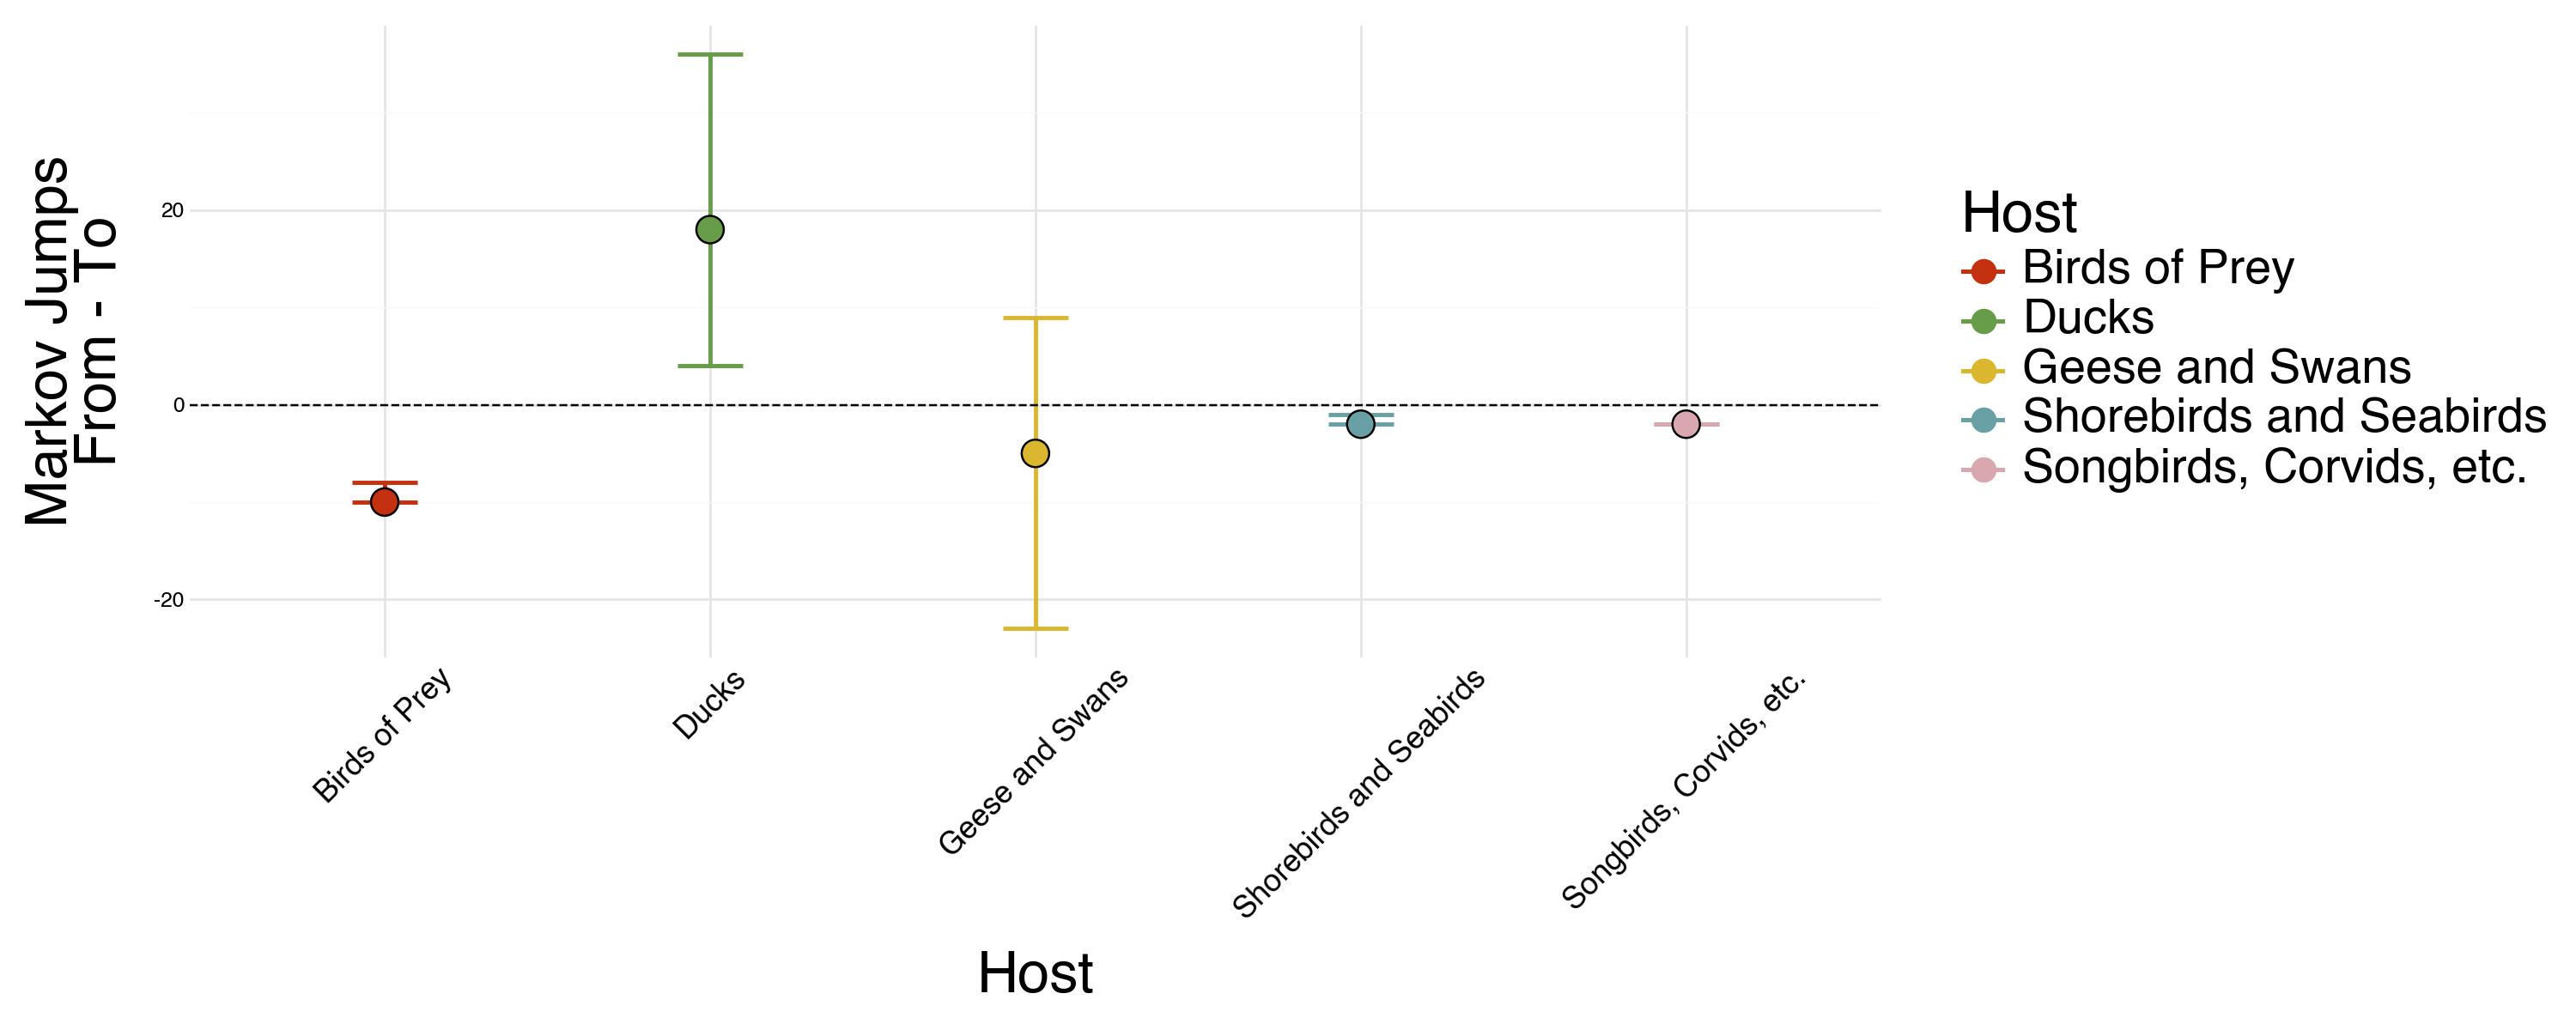

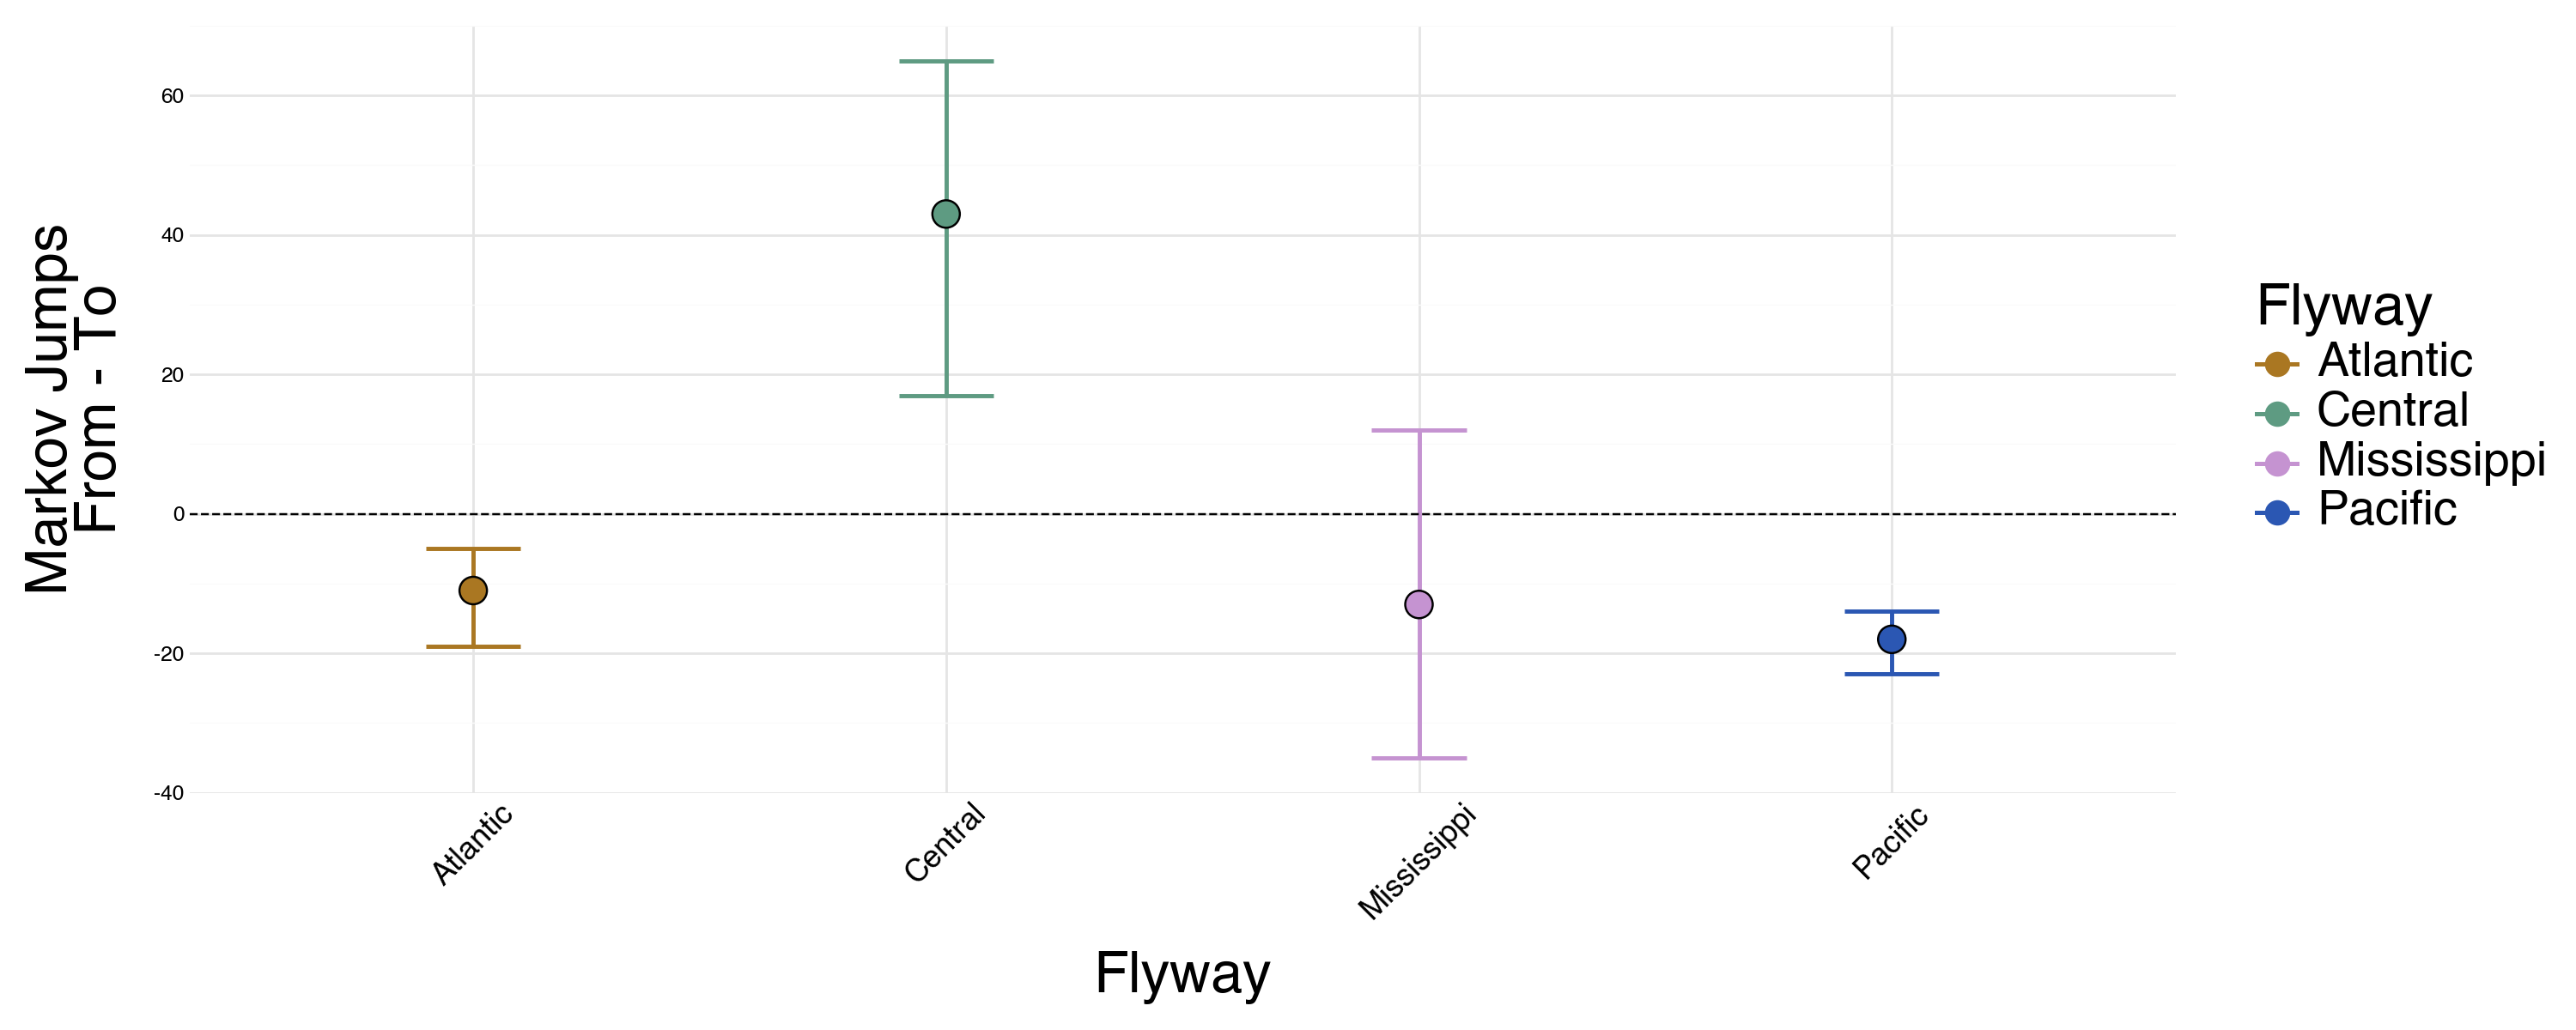

In [175]:
plt1A = (
    ggplot(data = host_source_sink[host_source_sink["source_sink"] == "net"])
    + geom_errorbar(aes(x = "trait", ymin = "lower", ymax = "upper", color = "trait"), width = 0.2, size = 1)
    + geom_point(aes(x = "trait", y = "median"), color = "black", size = 6)
    + geom_point(aes(x = "trait", y = "median", color = "trait"), size = 5)
    + geom_hline(yintercept = 0, linetype = "dashed")
    + scale_color_manual(values = host_colors, labels = host_labels)
    + scale_x_discrete(labels=host_labels)
    + labs(x = "Host", y = "Markov Jumps\nFrom - To", color = "Host")
    + theme_minimal()
    + theme(figure_size = (15,6), 
            legend_title = element_text(size = 24), legend_text=element_text(size=20), 
            axis_title_x = element_text(size = 24), axis_text_y = element_text(color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 13, rotation = 45, color = "black"))
)

plt1B = (
    ggplot(data = flyway_source_sink[flyway_source_sink["source_sink"] == "net"])
    + geom_errorbar(aes(x = "trait", ymin = "lower", ymax = "upper", color = "trait"), width = 0.2, size = 1)
    + geom_point(aes(x = "trait", y = "median"), color = "black", size = 6)
    + geom_point(aes(x = "trait", y = "median", color = "trait"), size = 5)
    + geom_hline(yintercept = 0, linetype = "dashed")
    + scale_color_manual(values = flyway_colors, labels = flyway_labels)
    + scale_x_discrete(labels=flyway_labels)
    + labs(x = "Flyway", y = "Markov Jumps\nFrom - To", color = "Flyway")
    + theme_minimal()
    + theme(figure_size = (15,6), 
            legend_title = element_text(size = 24), legend_text=element_text(size=20), 
            axis_title_x = element_text(size = 24), axis_text_y = element_text(color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 13, rotation = 45, color = "black"))
)

plt1A.show()
plt1B.show()

In [176]:
def counting_recipients(jumps, prob):

    to_from_list = []

    for (ori_name, tree), df in jumps.groupby(["origin", "treeNumber"]):
        for destination, df_1 in df.groupby("destination"):
            dest_name = destination
            numb = len(df_1)
            to_from_list.append({"treeNumber": tree, "origin": ori_name, "destination": dest_name, "count": numb})

    to_from_df = pd.DataFrame(to_from_list)
    to_from_df["combo"] = to_from_df["origin"] + "," + to_from_df["destination"]

    to_from_hdi = []

    for combo, df in to_from_df.groupby("combo"):
        hdi = az.hdi(df["count"], hdi_prob = prob).to_dataframe().reset_index()
        lower = hdi["x"].iloc[0]
        upper = hdi["x"].iloc[1]
        median = df["count"].median()
        to_from_hdi.append({"origin":combo.split(",")[0], "destination":combo.split(",")[1], "lower":lower, "median":median, "upper":upper})

    to_from_hdi_df = pd.DataFrame(to_from_hdi)

    return(to_from_df, to_from_hdi_df)

In [177]:
host_to_from, hdi_host_to_from = counting_recipients(hostjumps, 0.95)
flyway_to_from, hdi_flyway_to_from = counting_recipients(flywayjumps, 0.95)

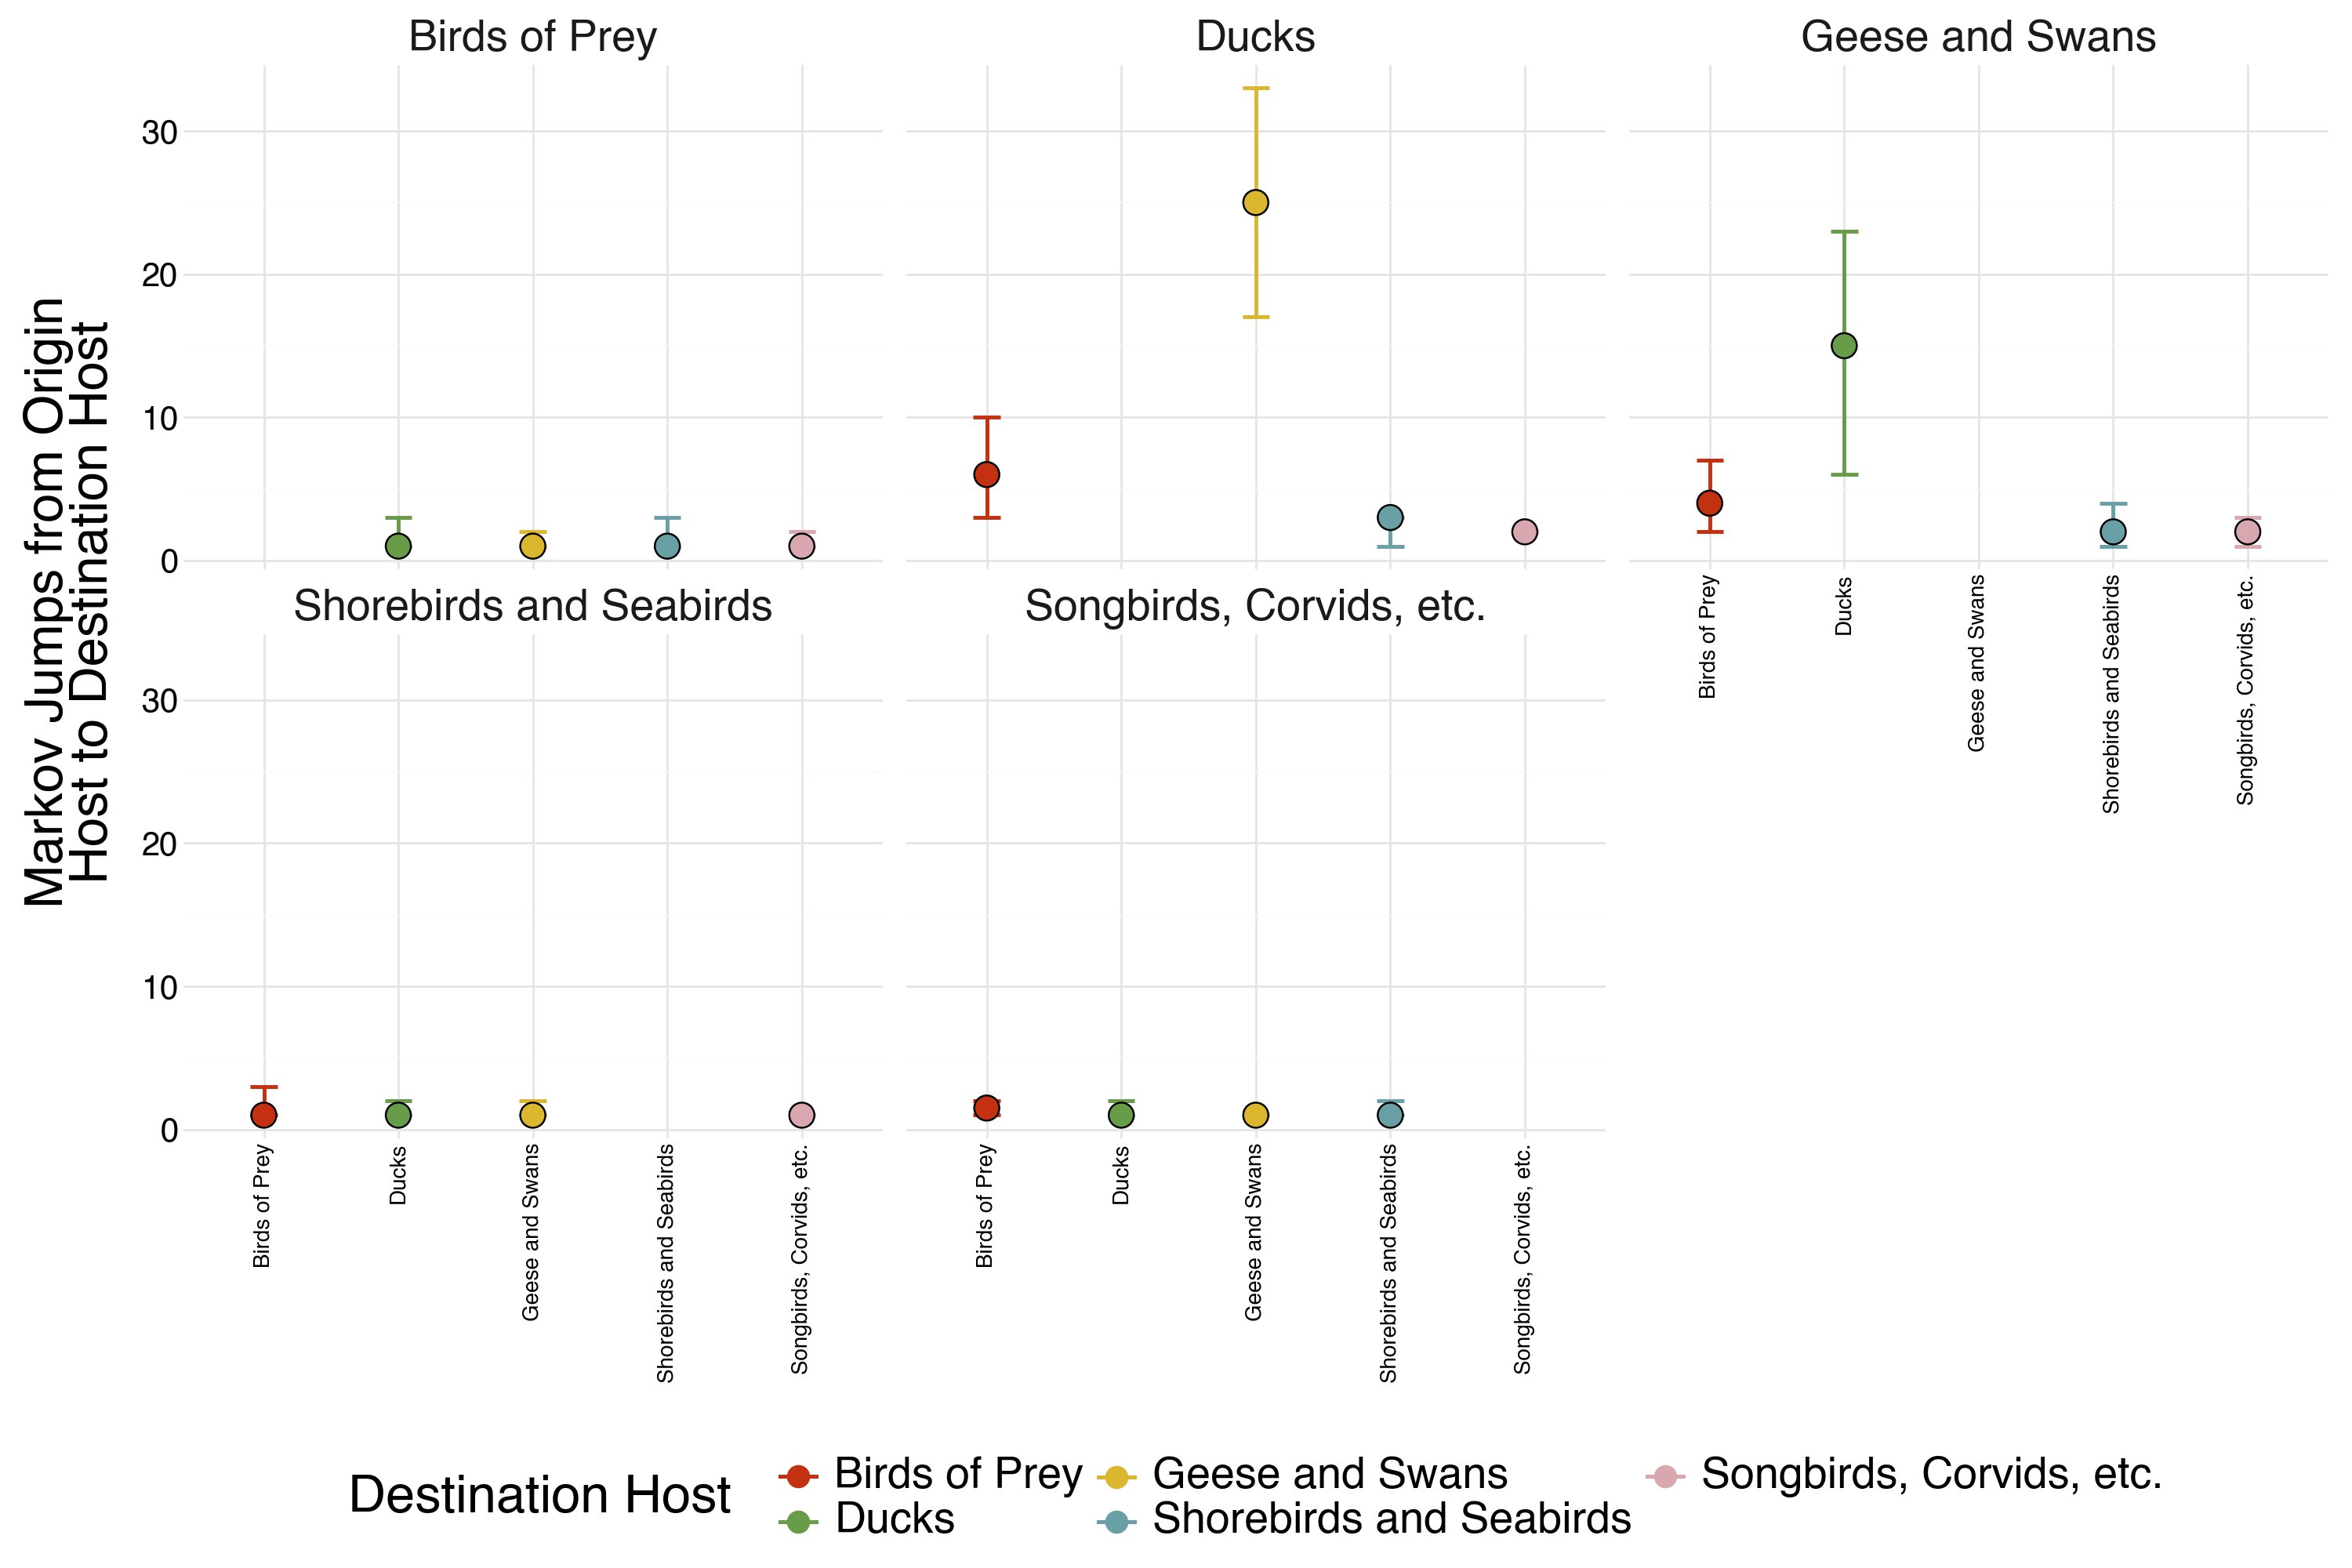

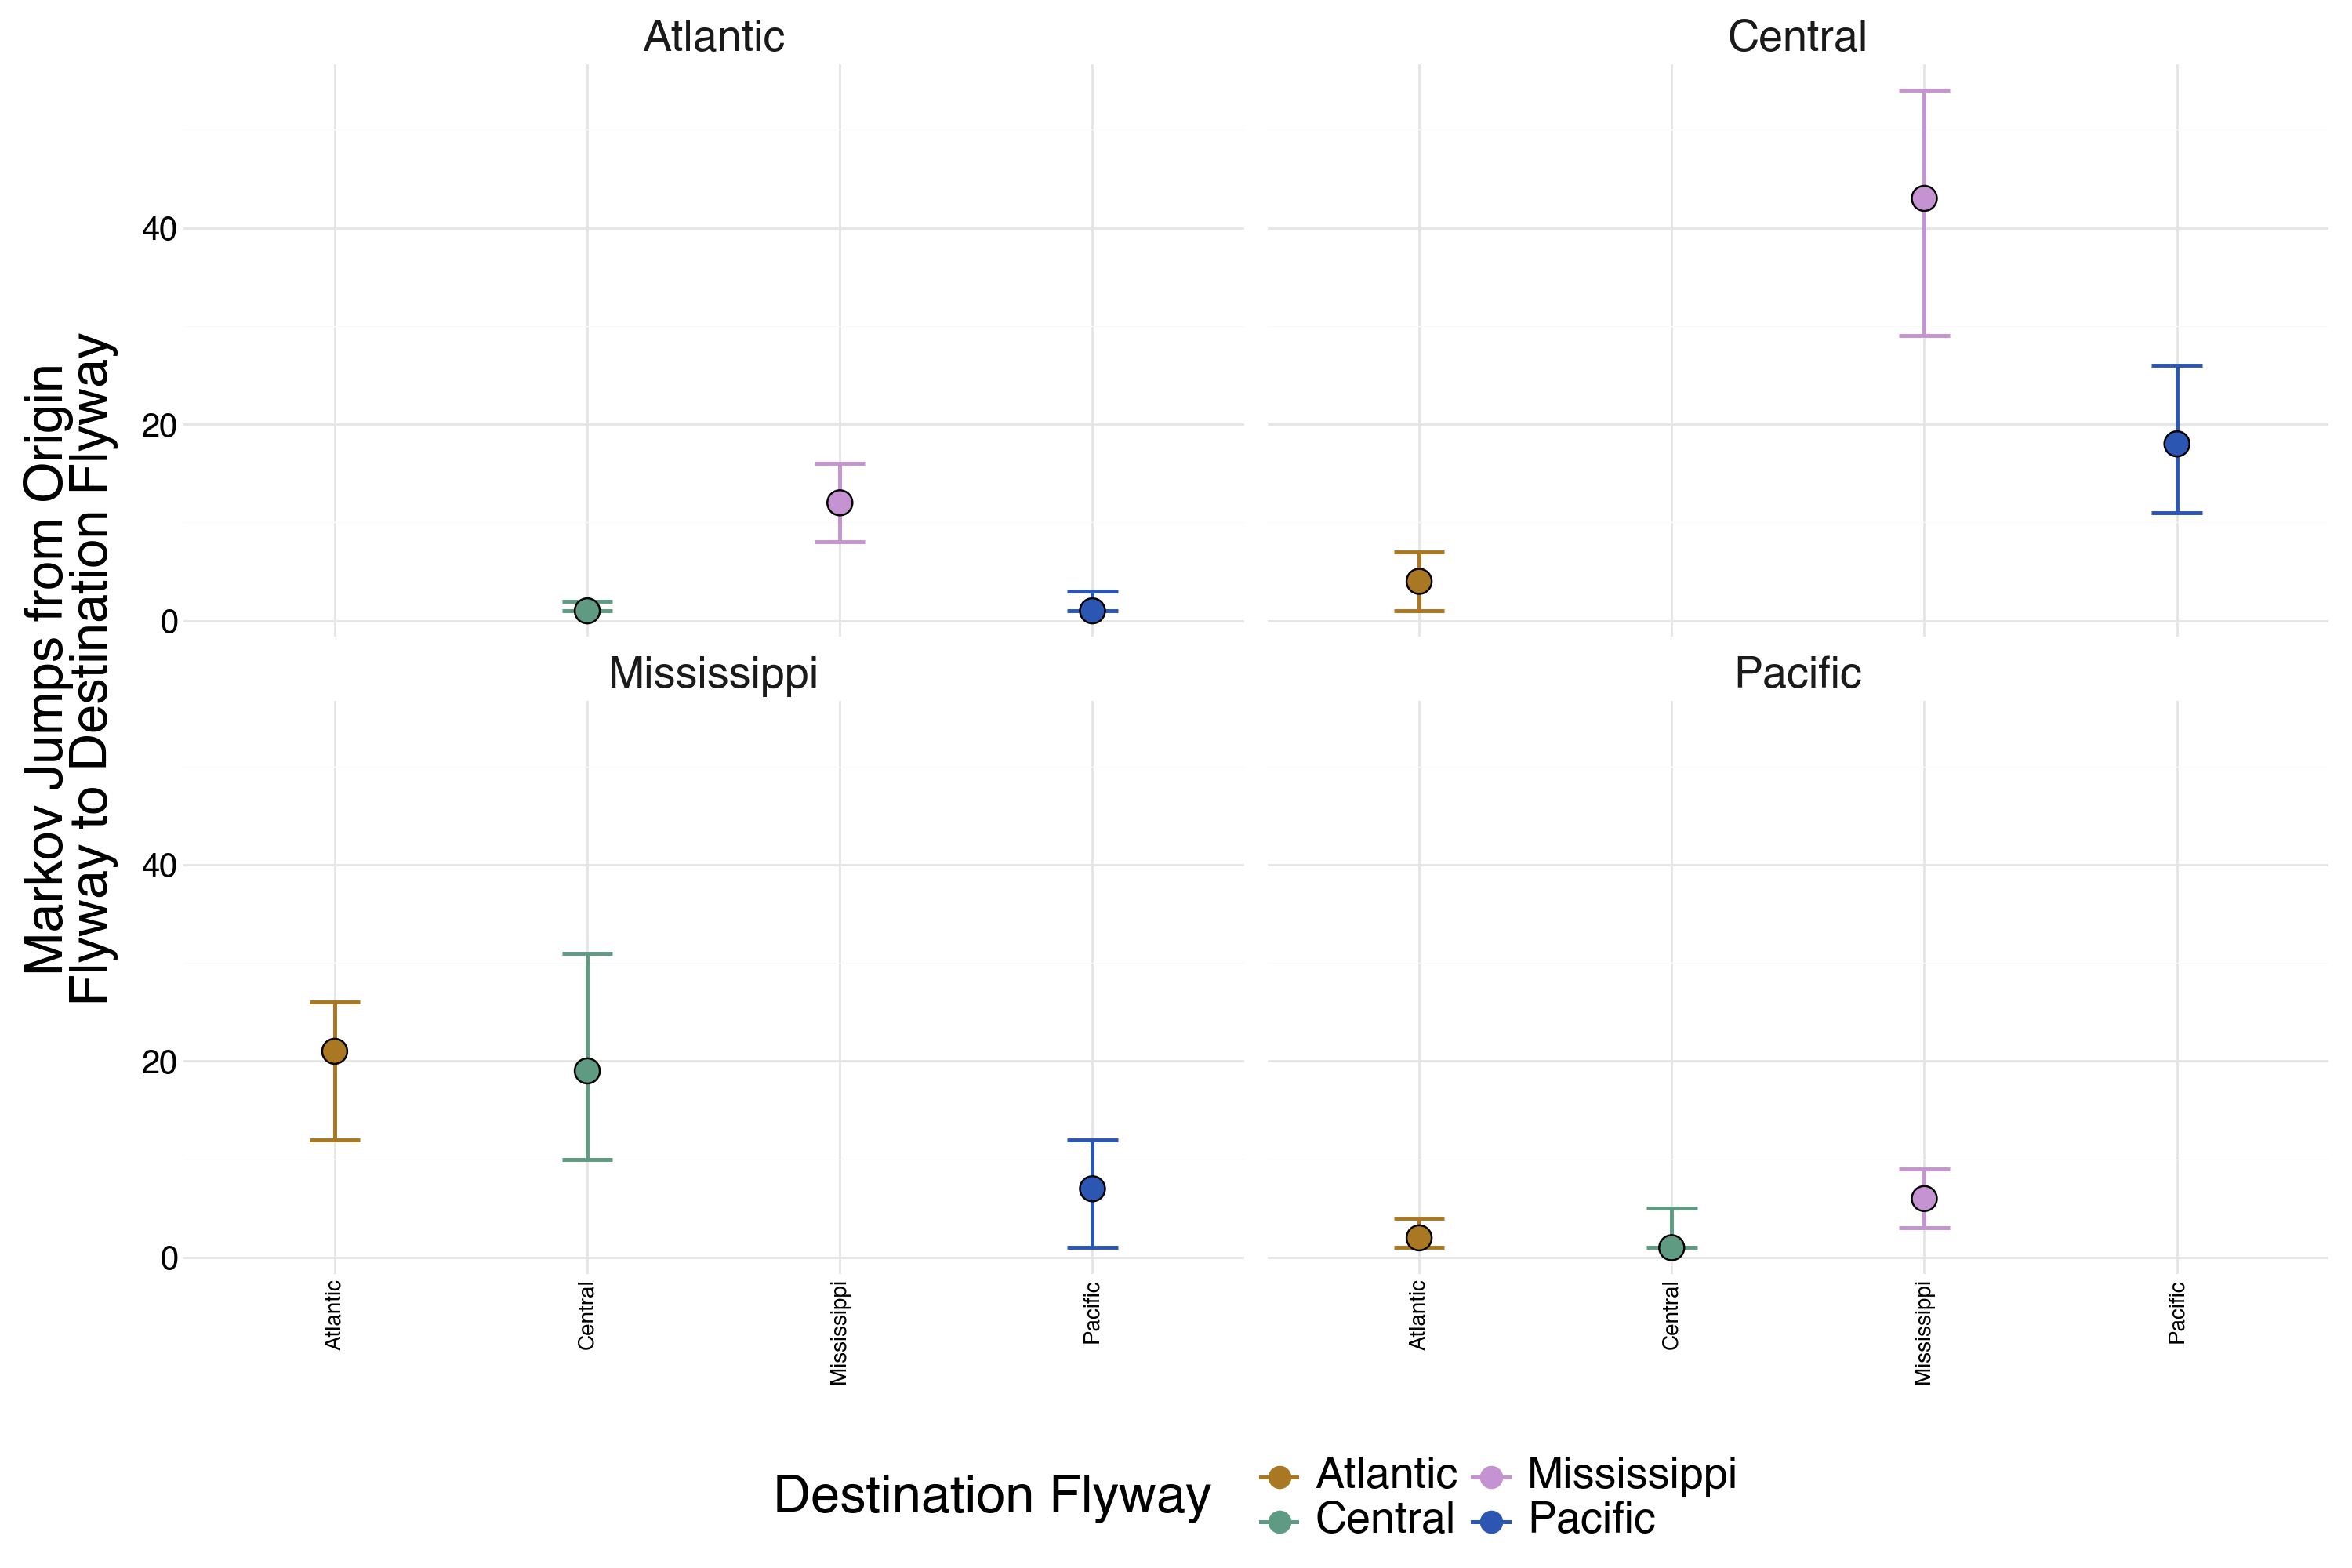

In [178]:
plt2A = (
    ggplot(hdi_host_to_from)
    + geom_errorbar(aes(x = "destination", ymin = "lower", ymax = "upper", color = "destination"), width = 0.2, size = 1)
    + geom_point(aes(x = "destination", y = "median"), color = "black", size = 6)
    + geom_point(aes(x = "destination", y = "median", color = "destination"), size = 5)
    + facet_wrap("origin", labeller = host_labels)
    + labs(x = "", y = "Markov Jumps from Origin\nHost to Destination Host", color = "Destination Host")
    + scale_x_discrete(labels=host_labels)
    + scale_color_manual(values = host_colors, labels = host_labels)
    + theme_minimal()
    + theme(figure_size = (15,10), text=element_text(size=20),
            legend_title = element_text(size = 24), legend_text=element_text(size=20), legend_position = "bottom", legend_direction = "horizontal",
            axis_title_x = element_text(size = 24), axis_text_y = element_text(size = 15, color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 10, rotation = 90, color = "black"))
    + guides(color=guide_legend(nrow=2), fill=guide_legend(nrow=2))
)

plt2B = (
    ggplot(hdi_flyway_to_from)
    + geom_errorbar(aes(x = "destination", ymin = "lower", ymax = "upper", color = "destination"), width = 0.2, size = 1)
    + geom_point(aes(x = "destination", y = "median"), color = "black", size = 6)
    + geom_point(aes(x = "destination", y = "median", color = "destination"), size = 5)
    + facet_wrap("origin", labeller = flyway_labels)
    + labs(x = "", y = "Markov Jumps from Origin\nFlyway to Destination Flyway", color = "Destination Flyway")
    + scale_x_discrete(labels=flyway_labels)
    + scale_color_manual(values = flyway_colors, labels = flyway_labels)
    + theme_minimal()
    + theme(figure_size = (15,10), text=element_text(size=20),
            legend_title = element_text(size = 24), legend_text=element_text(size=20), legend_position = "bottom", legend_direction = "horizontal",
            axis_title_x = element_text(size = 24), axis_text_y = element_text(size = 15, color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 10, rotation = 90, color = "black"))
    + guides(color=guide_legend(nrow=2), fill=guide_legend(nrow=2))
)

plt2A.show()
plt2B.show()

In [179]:
# Function: count the jumps from each group over time and then calculate the 95% HPD and median for plotting

def counting_jumps_overtime(jumps, group, prob):

    cumul_rows = []

    for (each, tree), df in jumps.groupby([group, "treeNumber"]):
        df["month_bin"] = np.floor(df["date"] * 12) / 12 # multiplies date by 12, finds the largest possible integer, and divides by 12 again
        df = df.sort_values("month_bin")
        df["cumul_count"] = range(1, len(df) + 1) # ChatGPT suggested this to count the cumulative instances of trait changes
        # print(df)
        columns = ["treeNumber", "date", "month_bin", f"{group}", "cumul_count"]
        cumul_rows.append(df.loc[:, columns])
        # print(cumul_rows)

    cumulative = pd.concat(cumul_rows) # This is a dataframe of cumulative transitions from each host per tree

    hdi_dict = []

    # Now group by month and origin host and calculate median and 95% HPD cumulative counts
    for (each, month), df in cumulative.groupby([group, "month_bin"]):
        each_hdi = az.hdi(df["cumul_count"], hdi_prob = prob).to_dataframe().reset_index()
        lower = each_hdi["x"].iloc[0] # Lower bound of 95% interval
        upper = each_hdi["x"].iloc[1] # Upper bound of 95% interval
        median = df["cumul_count"].median()
        # print(lower, upper, median)
        hdi_dict.append({"month": month, group: f"{each}", "lower": lower, "upper": upper, "median":median})

    hdi_df = pd.DataFrame(hdi_dict)
    # print(hdi_df)
    
    return(cumulative, hdi_df)

In [180]:
host_overtime, hdi_host_overtime = counting_jumps_overtime(hostjumps, "origin", 0.95)
flyway_overtime, hdi_flyway_overtime = counting_jumps_overtime(flywayjumps, "origin", 0.95)

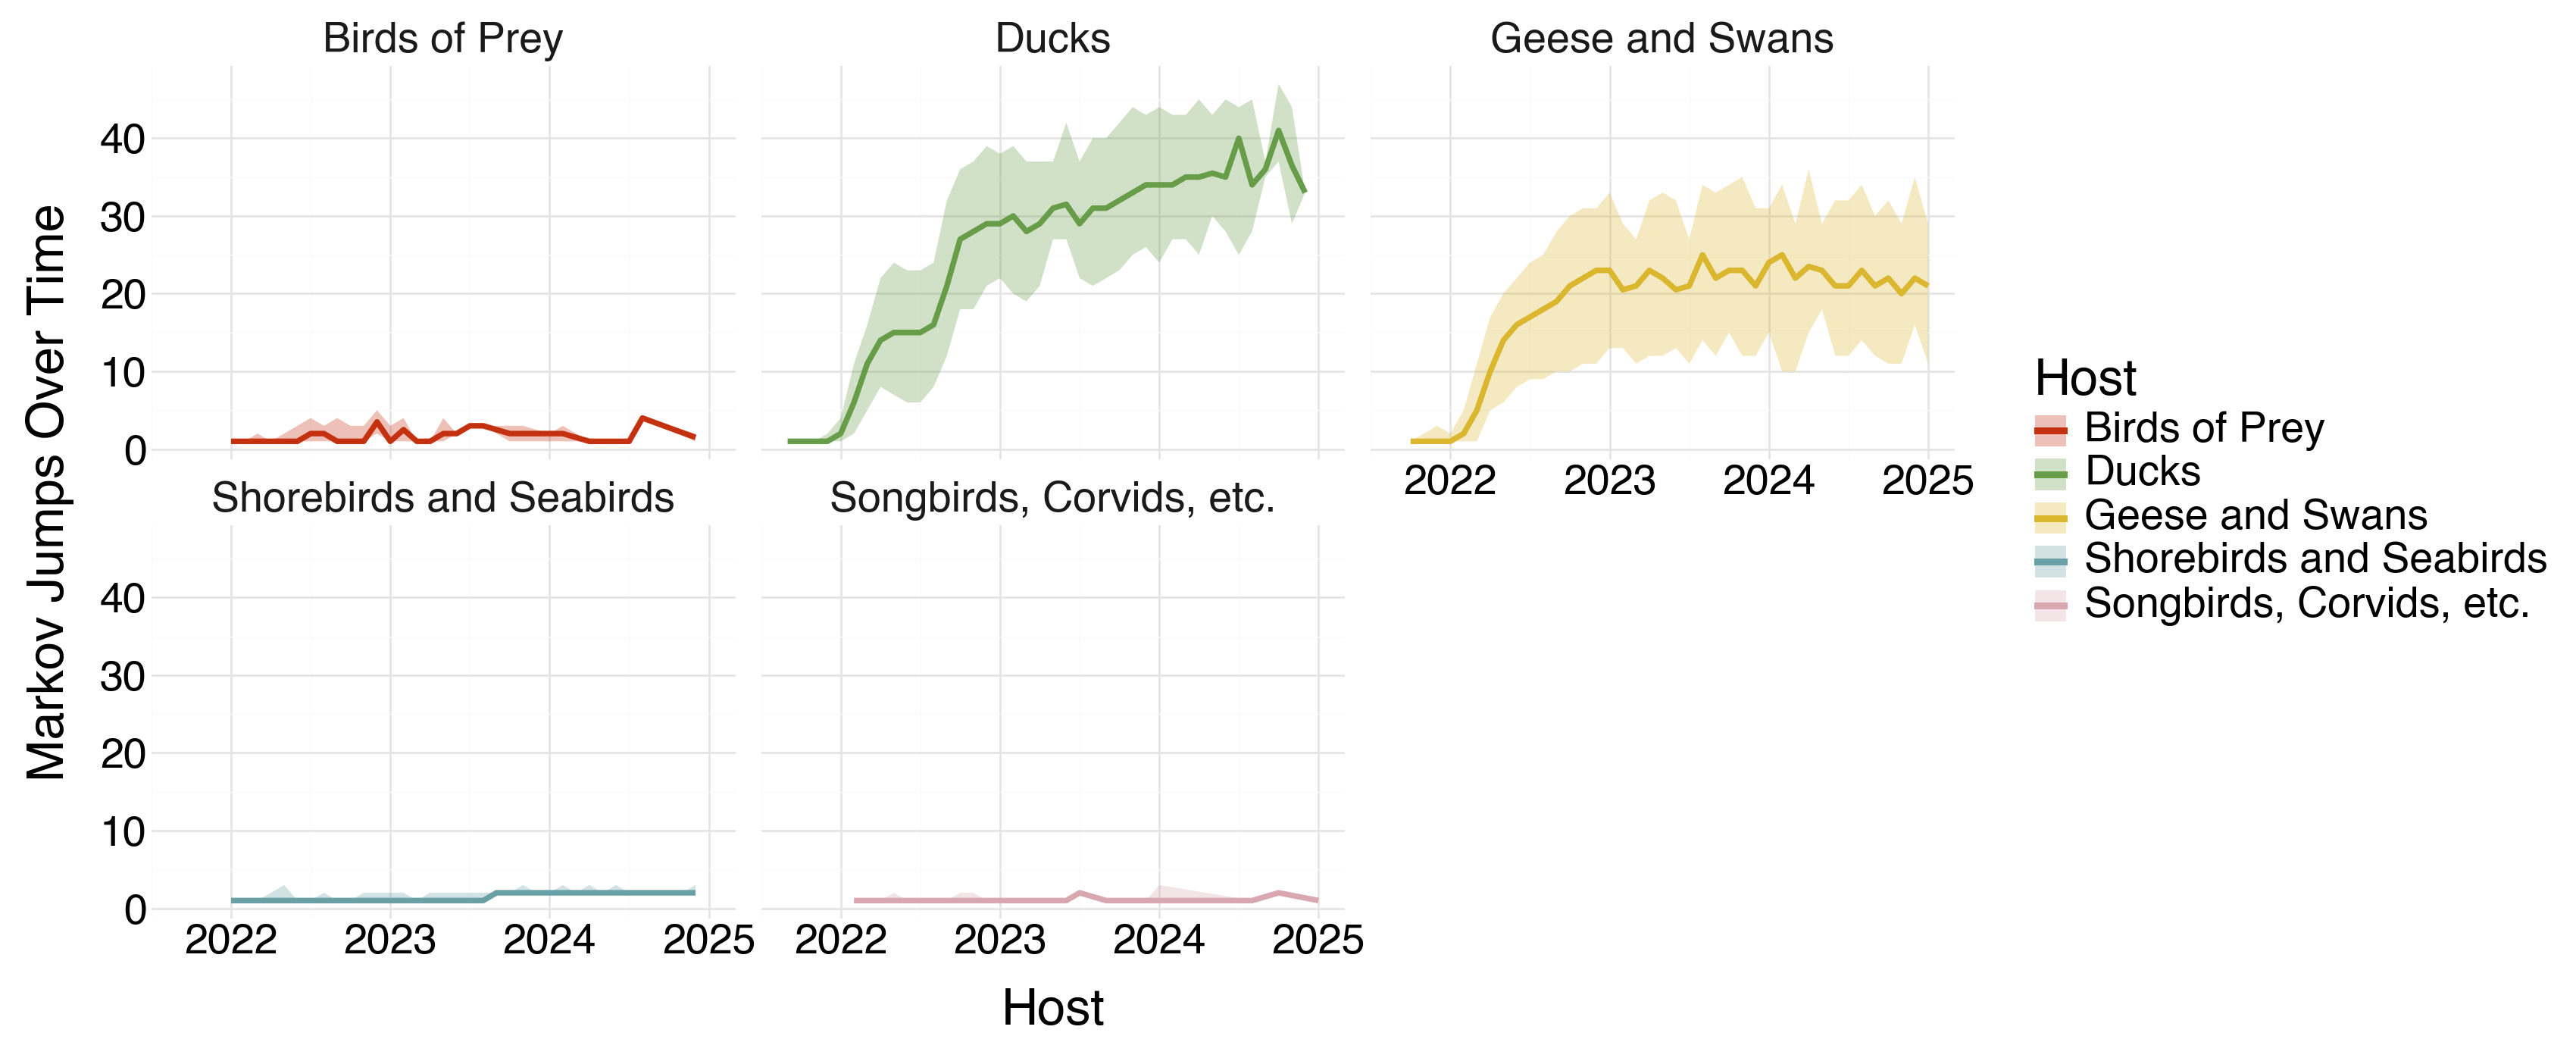

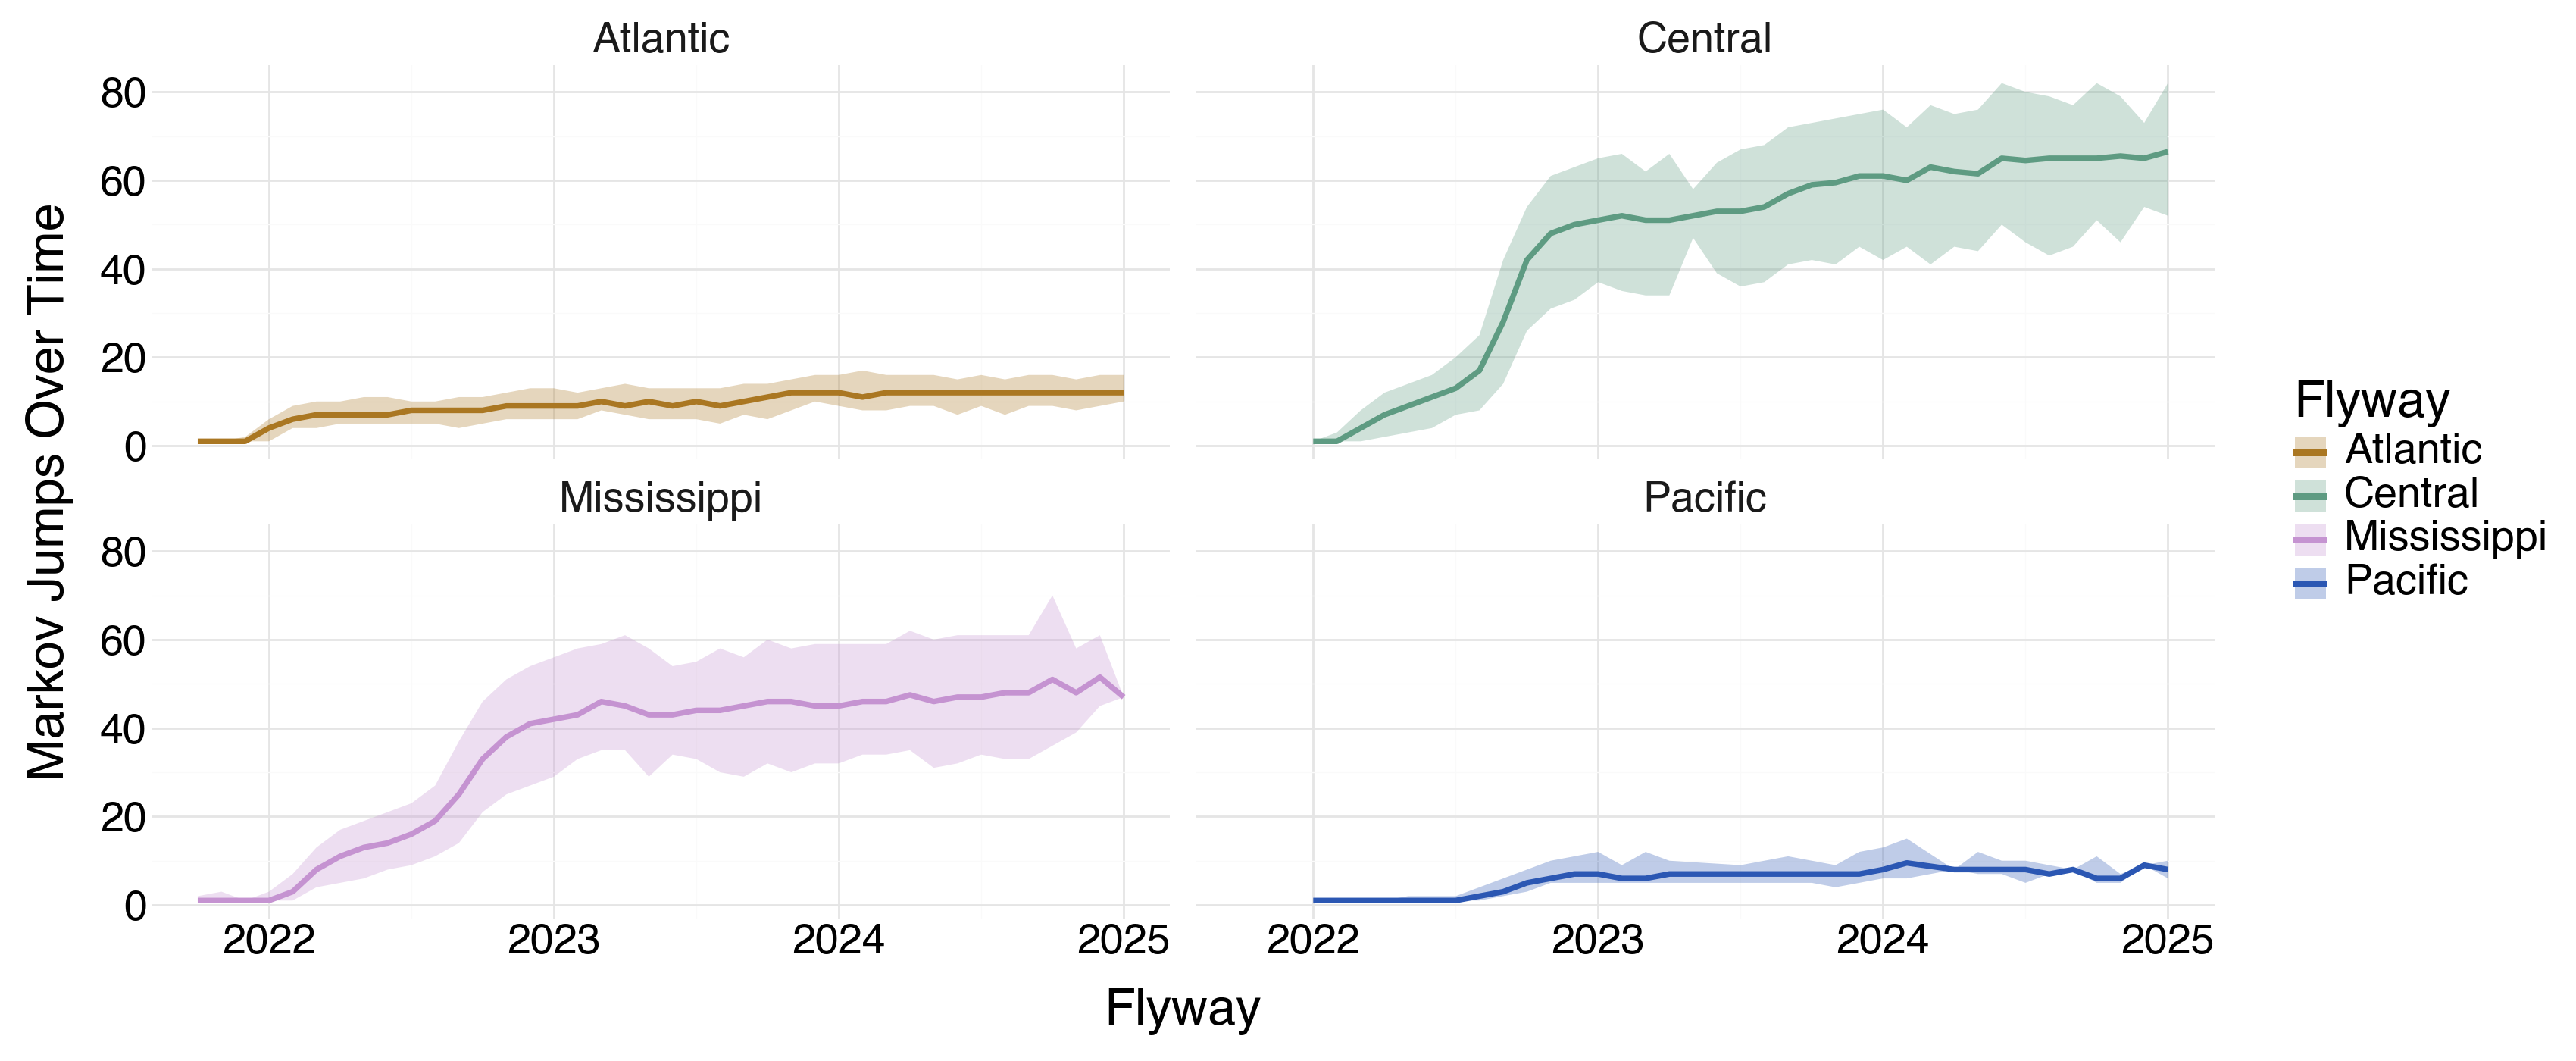

In [181]:
plt3A = (
    ggplot(hdi_host_overtime, aes(x = "month", group = "origin"))
    + geom_ribbon(aes(ymin = "lower", ymax = "upper", fill = "origin"), alpha = 0.3)
    + geom_line(aes(y = "median", color = "origin"), size = 1.5)
    + facet_wrap("origin", labeller = host_labels)
    + scale_color_manual(values = host_colors, labels = host_labels)
    + scale_fill_manual(values = host_colors, labels = host_labels)
    + labs(x = "Host", y = "Markov Jumps Over Time", color = "Host", fill = "Host")
    + theme_minimal()
    + theme(figure_size = (17,7), text=element_text(size=20),
            legend_title = element_text(size = 24), legend_text=element_text(size=20), 
            axis_title_x = element_text(size = 24), axis_text_y = element_text(color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 20, color = "black"))
)

plt3B = (
    ggplot(hdi_flyway_overtime, aes(x = "month", group = "origin"))
    + geom_ribbon(aes(ymin = "lower", ymax = "upper", fill = "origin"), alpha = 0.3)
    + geom_line(aes(y = "median", color = "origin"), size = 1.5)
    + facet_wrap("origin", labeller = flyway_labels)
    + scale_color_manual(values = flyway_colors, labels = flyway_labels)
    + scale_fill_manual(values = flyway_colors, labels = flyway_labels)
    + labs(x = "Flyway", y = "Markov Jumps Over Time", color = "Flyway", fill = "Flyway")
    + theme_minimal()
    + theme(figure_size = (17,7), text=element_text(size=20),
            legend_title = element_text(size = 24), legend_text=element_text(size=20), 
            axis_title_x = element_text(size = 24), axis_text_y = element_text(color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 20, color = "black"))
)

plt3A.show()
plt3B.show()

In [182]:
# Function: compute overall rewards from log file

def compute_rewards_hpd(LOGPATH, columns, label_dict):

    log = pd.read_csv(LOGPATH, sep = "\t") #read in the log file

    needed_columns = [] # I don't want to change the column list every time
    for i in columns:
        if i in log.columns:
            needed_columns.append(i) # Just grab the rewards columns that are there

    log_rewards = log[needed_columns]

    log_rewards_hpd = log_rewards.apply(lambda col: az.hdi(col.values, hdi_prob=0.95)).T # compute 95% HPD
    log_rewards_hpd.columns = ["lower", "upper"]
    log_rewards_hpd["median"] = log_rewards.median() # Compute median

    log_rewards_hpd["trait"] = log_rewards_hpd.index.str.replace("_reward[1]", "").str.replace("c_", "") # Extract trait name
    log_rewards_hpd["label"] = log_rewards_hpd["trait"].map(label_dict)

    return(log_rewards_hpd)

In [183]:
# Extract the overall rewards across the posterior and compute the 95% HPD and median

LOGPATH = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_liveharvest_ha_traits_mjr/main-intro_liveharvest_ha_traits_combined.log"

host_reward_columns = ["c_bird-of-prey_reward[1]", "c_duck_reward[1]", "c_goose-swan_reward[1]", "c_shorebird_reward[1]", "c_songbird-etc_reward[1]", "c_other_reward[1]", "c_diving-bird_reward[1]", "c_ground-bird_reward[1]"]
flyway_reward_columns = ["c_AtlanticFlyway_reward[1]", "c_CentralFlyway_reward[1]", "c_MississippiFlyway_reward[1]", "c_PacificFlyway_reward[1]"]

host_rewards = compute_rewards_hpd(LOGPATH, host_reward_columns, host_labels)
flyway_rewards = compute_rewards_hpd(LOGPATH, flyway_reward_columns, flyway_labels)

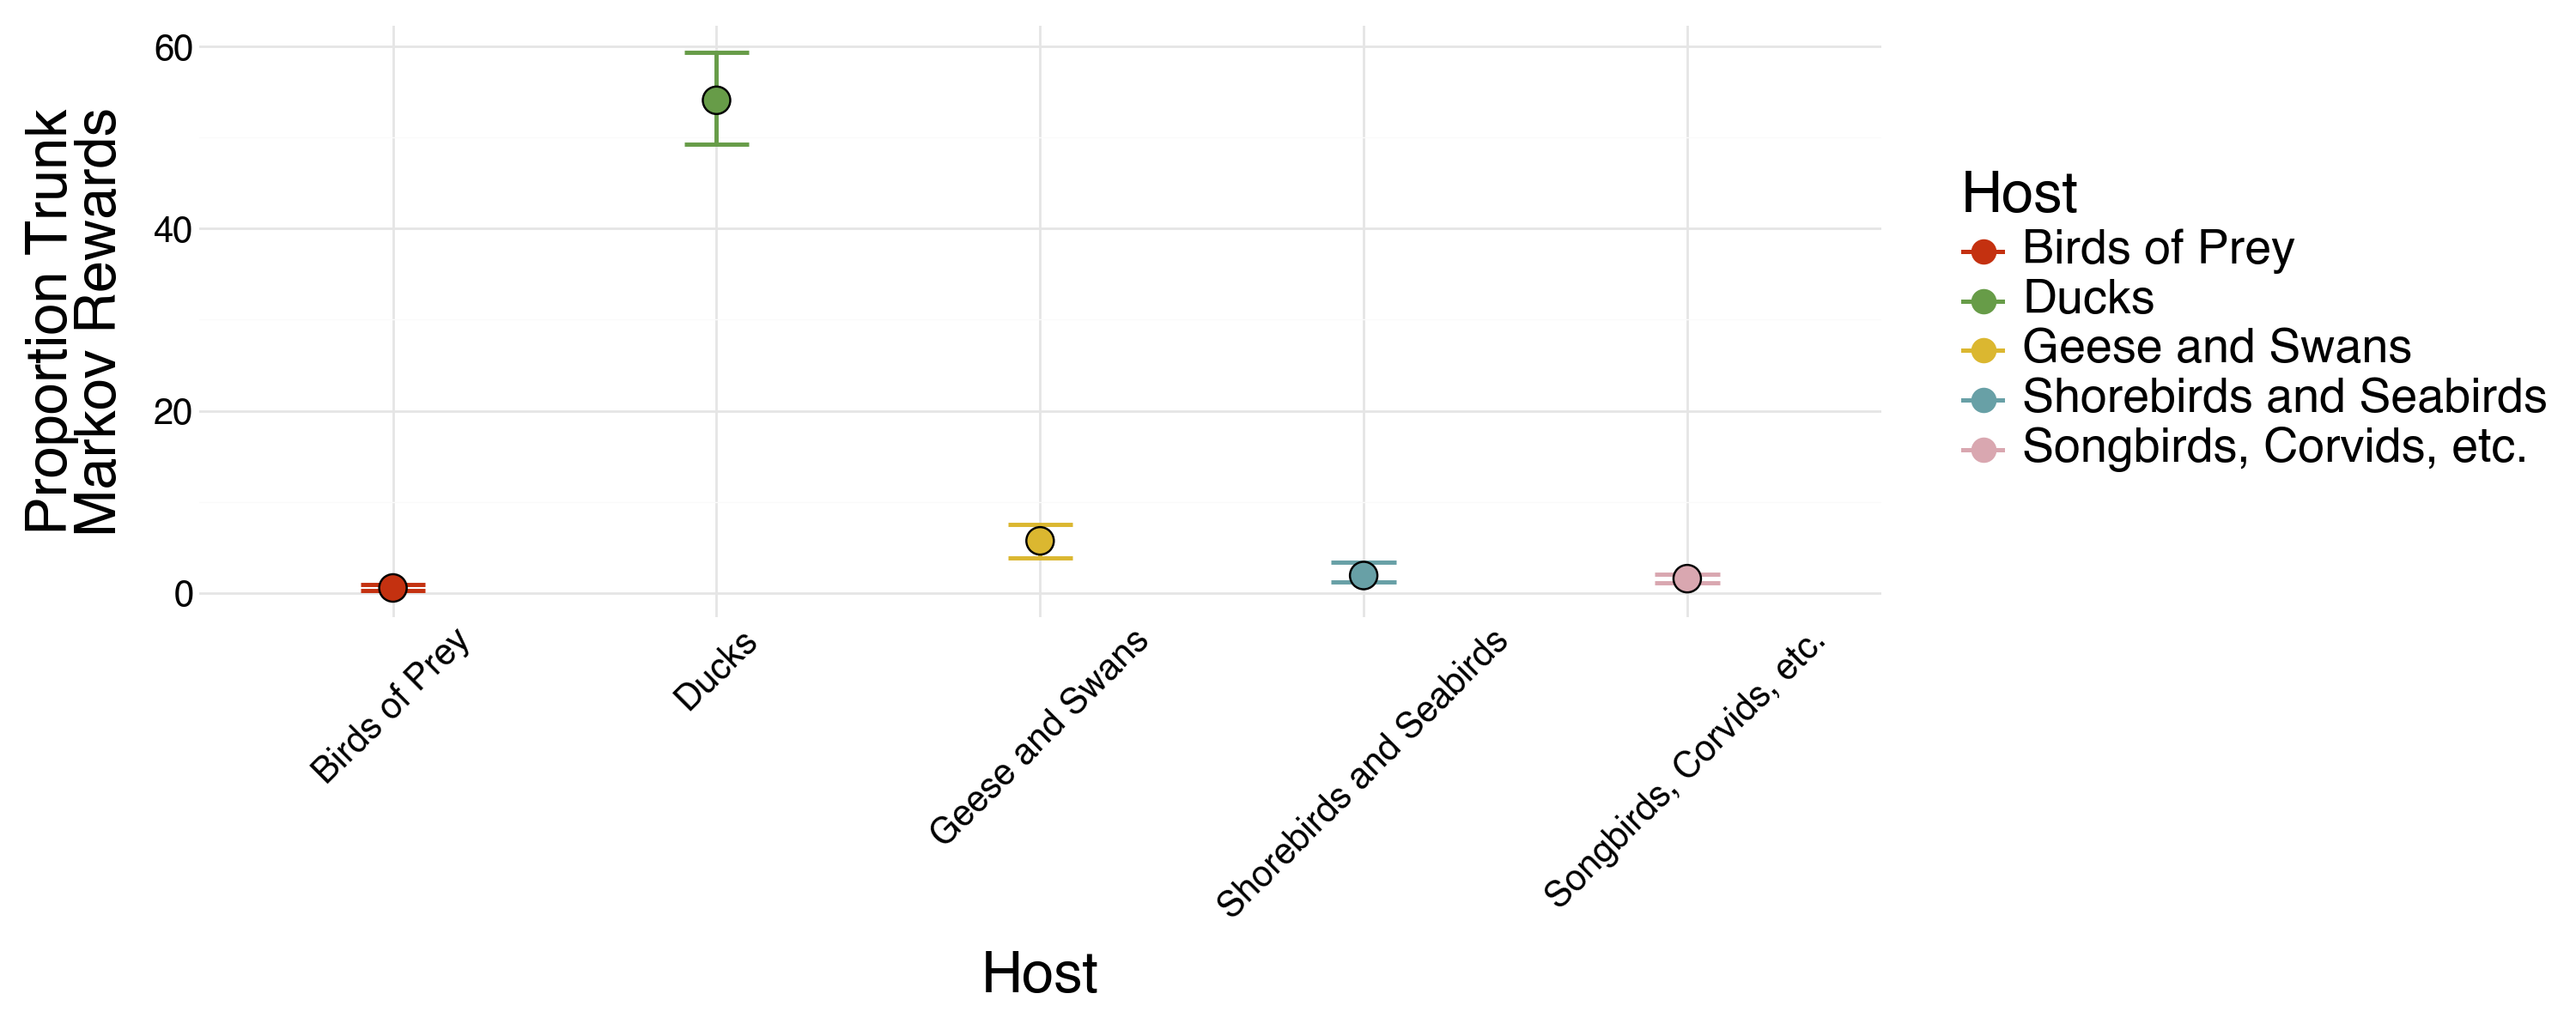

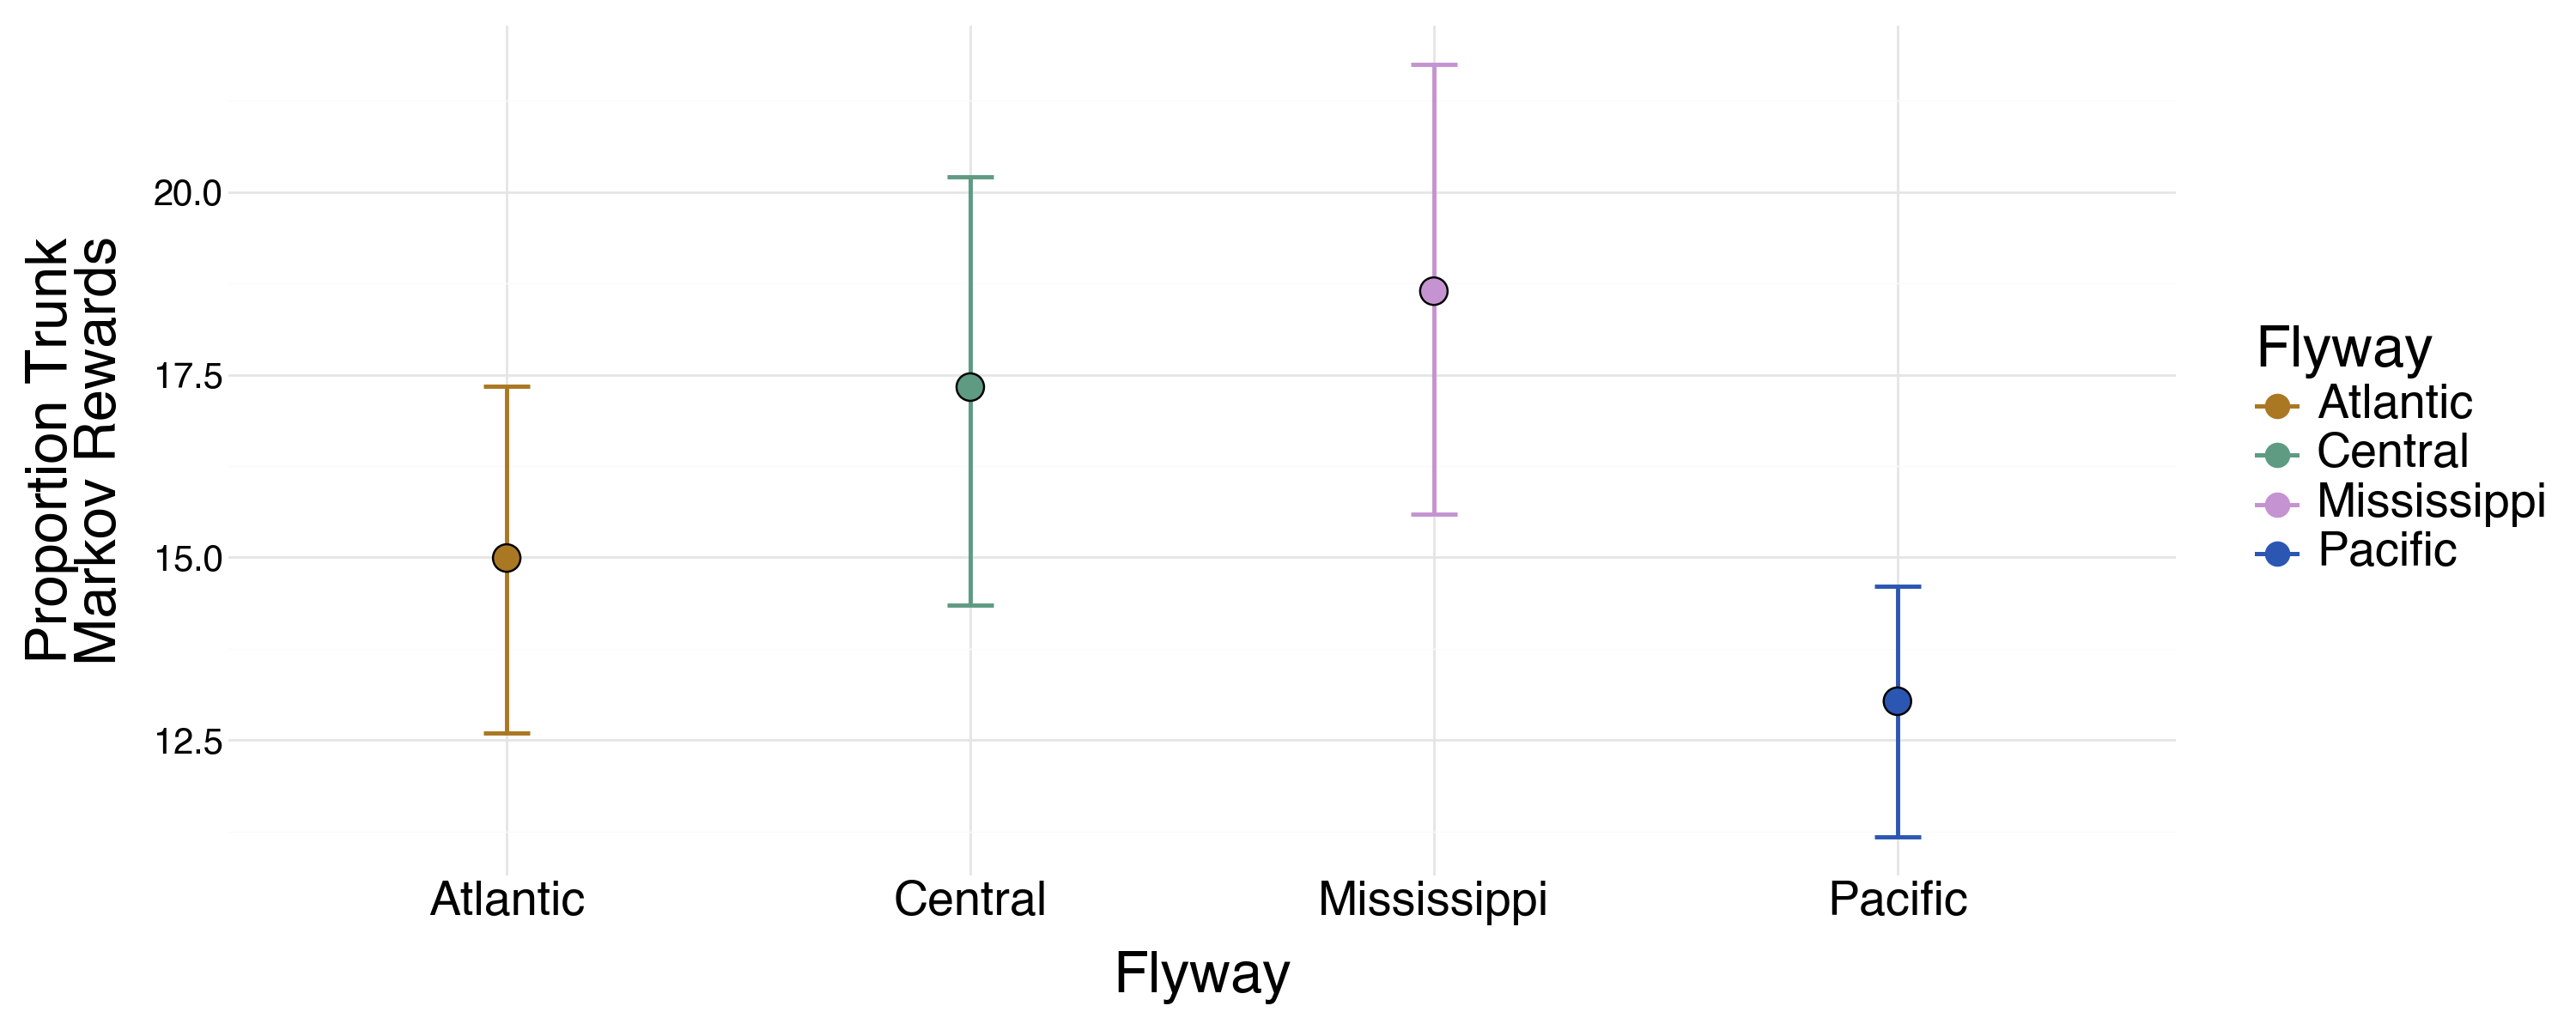

In [184]:
plt4A = (
    ggplot(host_rewards)
    + geom_errorbar(aes(x = "label", ymin = "lower", ymax = "upper", color = "trait"), width = 0.2, size = 1)
    + geom_point(aes(x = "label", y = "median"), color = "black", size = 6)
    + geom_point(aes(x = "label", y = "median", color = "trait"), size = 5)
    + labs(x = "Host", y = "Proportion Trunk\nMarkov Rewards", color = "Host")
    + scale_color_manual(values = host_colors, labels = host_labels)
    + theme_minimal()
    + theme(figure_size = (15,6), 
            legend_title = element_text(size = 24), legend_text=element_text(size=20), 
            axis_title_x = element_text(size = 24), axis_text_y = element_text(size = 15, color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 15, rotation = 45, color = "black"))
)

plt4B = (
    ggplot(flyway_rewards)
    + geom_errorbar(aes(x = "label", ymin = "lower", ymax = "upper", color = "trait"), width = 0.1, size = 1)
    + geom_point(aes(x = "label", y = "median"), color = "black", size = 6)
    + geom_point(aes(x = "label", y = "median", color = "trait"), size = 5)
    + labs(x = "Flyway", y = "Proportion Trunk\nMarkov Rewards", color = "Flyway")
    + scale_color_manual(values = flyway_colors, labels = flyway_labels)
    + theme_minimal()
    + theme(figure_size = (15,6), 
            legend_title = element_text(size = 24), legend_text=element_text(size=20), 
            axis_title_x = element_text(size = 24), axis_text_y = element_text(size = 15, color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 20, rotation = 0, color = "black"))
)

plt4A.show()
plt4B.show()

In [185]:
def load_tree(nexusPath):
    mytree = bt.loadNexus(nexusPath, tip_regex='\|([0-9]{4}\-[0-9]{2}\-[0-9]{2})', absoluteTime=True, verbose=False) # your tip regex might have to change or you could convert you tree into a newick by deleting everything before the tree string lol
    return(mytree)

def compute_rewards_overtime(PATH, MRSD, root, traitType):

    tree = load_tree(PATH) # load the tree using the load_tree function above

    metadata = []

    for k in tree.Objects:
        if k.traits != None: # if k is not the root
            if traitType == "host":
                metadata.append({'branchType': k.branchType, 'height': k.traits.get("height"), "birdofprey_r": k.traits.get("birdofprey_reward"), "duck_r": k.traits.get("duck_reward"), "gooseswan_r": k.traits.get("gooseswan_reward"), "shorebird_r": k.traits.get("shorebird_reward"), "songbirdetc_r": k.traits.get("songbirdetc_reward")})
                # metadata.append({"branchType": k.branchType, "height": k.traits.get("height"), "birdofprey_r": k.traits.get("birdofprey_reward"), "diving_r": k.traits.get("divingbird_reward"), "duck_r": k.traits.get("duck_reward"), "gooseswan_r": k.traits.get("gooseswan_reward"), "groundbird_r": k.traits.get("groundbird_reward"), "other_r": k.traits.get("other_reward"), "shorebird_r": k.traits.get("shorebird_reward"), "songbirdetc_r": k.traits.get("songbirdetc_reward")})
            if traitType == "flyway":
                metadata.append({"branchType": k.branchType, "height": k.traits.get("height"), "AtlanticFlyway_r": k.traits.get("AtlanticFlyway_reward"), "MississippiFlyway_r": k.traits.get("MississippiFlyway_reward"), "CentralFlyway_r": k.traits.get("CentralFlyway_reward"), "PacificFlyway_r": k.traits.get("PacificFlyway_reward")})

    rewards_overtime = pd.DataFrame(metadata)

    rewards_overtime["date"] = MRSD - rewards_overtime["height"] # assign date using most recent sampling date and height

    rewards_prop = rewards_overtime.copy()

    rewards_columns = rewards_prop.columns[rewards_prop.columns.str.contains("_r", regex = False)] # Call all columns with rewards over time
    rewards_prop["total"] = rewards_prop.loc[:, rewards_columns].sum(axis = 1) # ChatGPT helped refine this line
    for each in rewards_columns:
        trait = each.split("_")[0]
        rewards_prop[f"{trait}_p"] = rewards_prop[each] / rewards_prop["total"] # Calculate the proportion of each trait
        if trait == root: # Set the trait proportion at the root
            rewards_prop.loc[rewards_prop.index == 0, f"{trait}_p"] = 1.0
        else:
            rewards_prop.loc[rewards_prop.index == 0, f"{trait}_p"] = 0.0

    keep_columns = ["branchType", "height", "date"] + [col for col in rewards_prop.columns if col.endswith("_p")] # ChatGPT helped me specify the second part of this
    rewards_prop_final = rewards_prop[keep_columns] # Make a final dataset to be used

    interval_width = 1/52.14 # Weekly intervals if 52.14 weeks in a year
    weekly_sequence = np.arange(rewards_prop_final["date"].min(), rewards_prop_final["date"].max() + interval_width, interval_width) # establish a weekly sequence

    # Divide the rewards proportion into weeks (ChatGPT guided me towards using the pd.cut command)
    rewards_prop_final["week"] = pd.cut(rewards_prop_final["date"], weekly_sequence, right = True, labels = weekly_sequence[:-1], include_lowest = True)

    wkdict = {}
    for i in rewards_prop_final.columns:
        if "_p" in i:
            state = i.split("_")[0]
            wkdict[f"{state}"] = rewards_prop_final.groupby("week")[i].mean() # Calculate the mean rewards per week for each state/trait

    weekly_rewards = pd.DataFrame(wkdict).reset_index()

    weekly_rewards_melted = pd.melt(weekly_rewards, id_vars = "week", var_name = "trait", value_name = "value")
    weekly_rewards_melted["week"] = pd.to_numeric(weekly_rewards_melted["week"])
    
    # print(weekly_rewards_melted)
    
    return(weekly_rewards_melted)

In [186]:
HOSTMCC = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_liveharvest_ha_traits_mjr/main-intro_liveharvest_ha_traits_MCC.host_EDITED.history.tree"
FLYWAYMCC = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_liveharvest_ha_traits_mjr/main-intro_liveharvest_ha_traits_MCC.flyway.history.tree"

MRSD = 2025.0438356164384 # Most recent sampling date

# eq-time-host-1000 - 2024.8989071038252
# eq-time-host-3000 - 2024.8989071038252
# prop-time-loc - 2024.9453551912568
# prop-time-host - 2024.9453551912568
# liveharvest - 2025.0438356164384
# Eq-time-loc - 2025.054794520548

weekly_host_rewards = compute_rewards_overtime(HOSTMCC, MRSD, "shorebird", traitType = "host")
weekly_flyway_rewards = compute_rewards_overtime(FLYWAYMCC, MRSD, "AtlanticFlyway", traitType = "flyway")

In [187]:
# Adjusted color dictionaries to deal with the removed hyphens

host_colors_2 = {"birdofprey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "gooseswan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbirdetc":"#D9A7B0", # pink
                     "groundbird":"#E08907", # orange
                     "divingbird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }

host_labels_2 = {"birdofprey":"Birds of Prey", # red-maroon
                     "duck":"Ducks", # green 
                     "gooseswan": "Geese and Swans", # yellow
                     "shorebird":"Shorebirds and Seabirds", # blue
                     "songbirdetc":"Songbirds, Corvids, etc.", # pink
                     "groundbird":"Ground Birds", # orange
                     "divingbird":"Diving Birds", # deep purple
                     "other":"Other" # grey
                    }

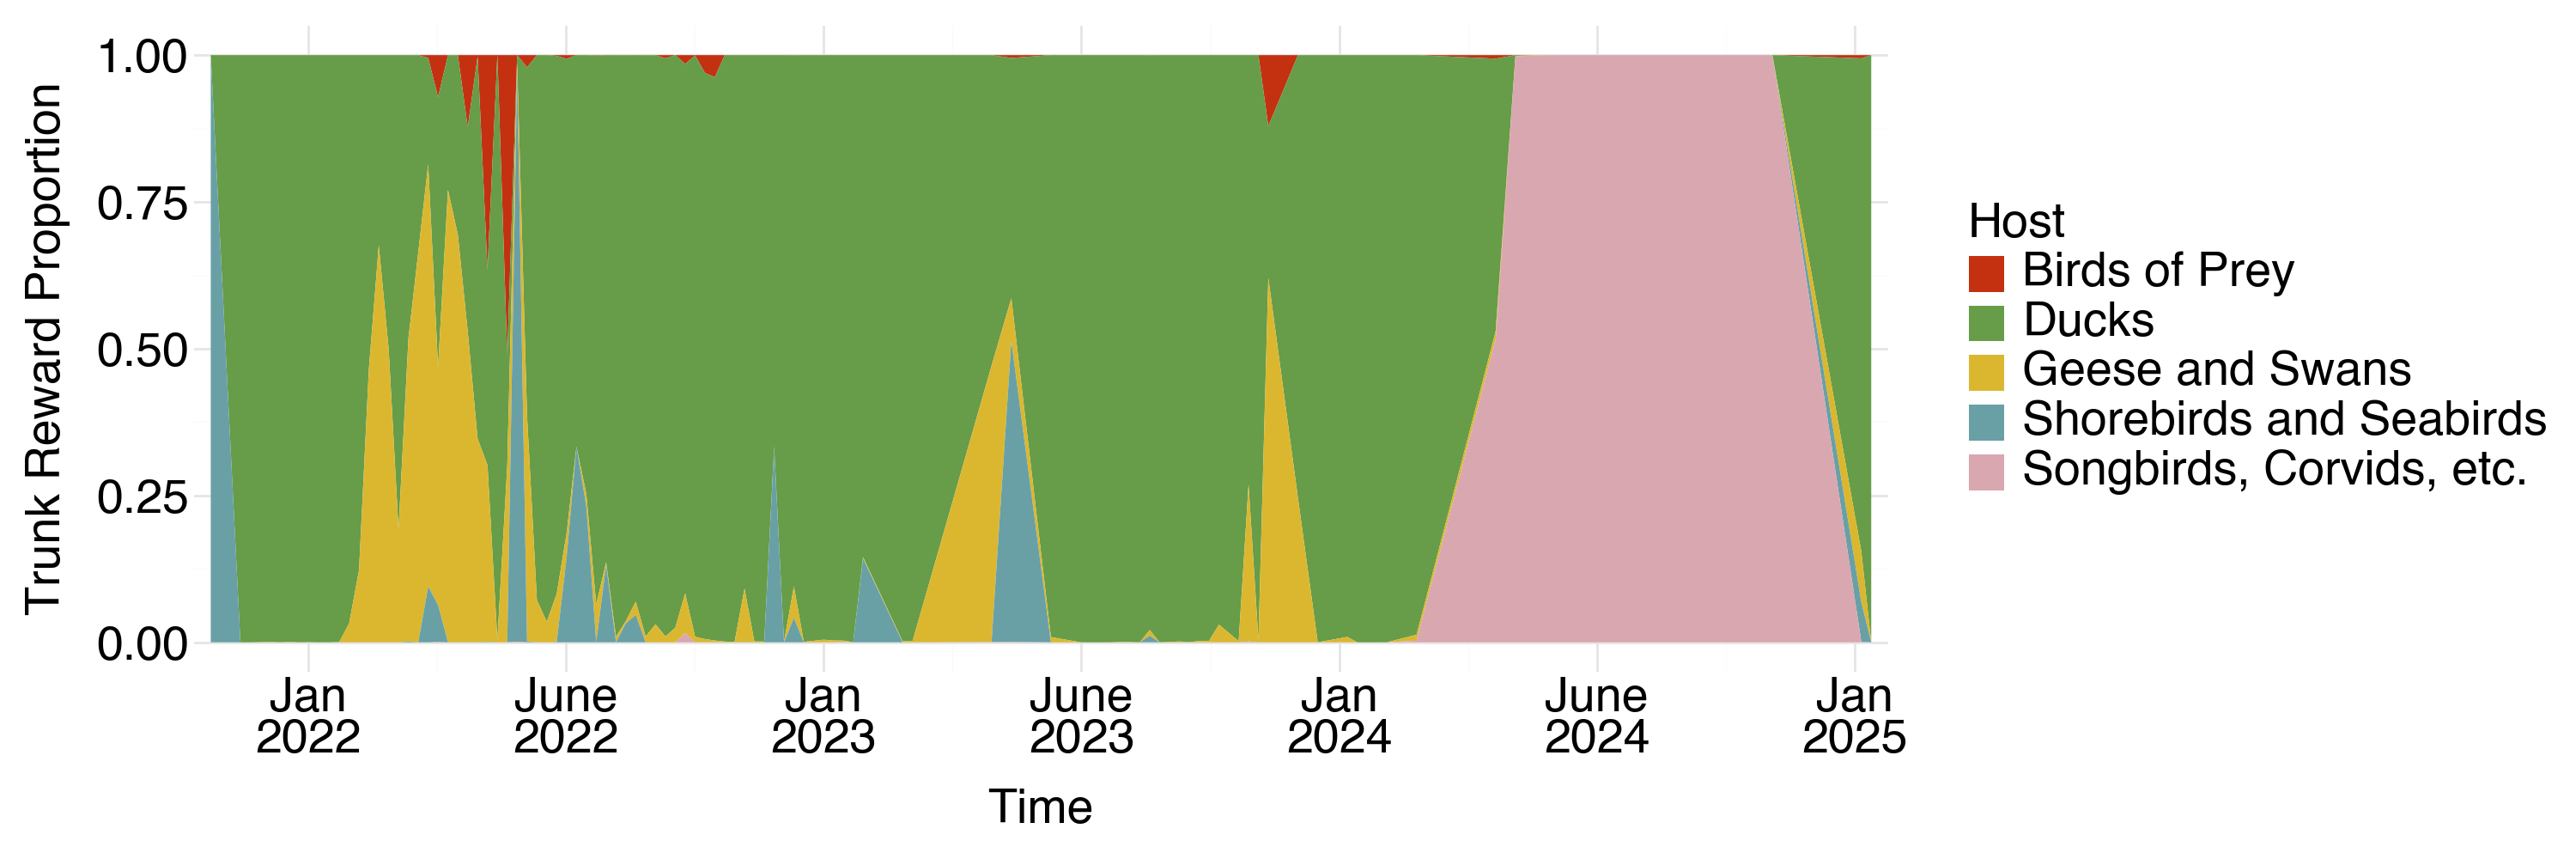

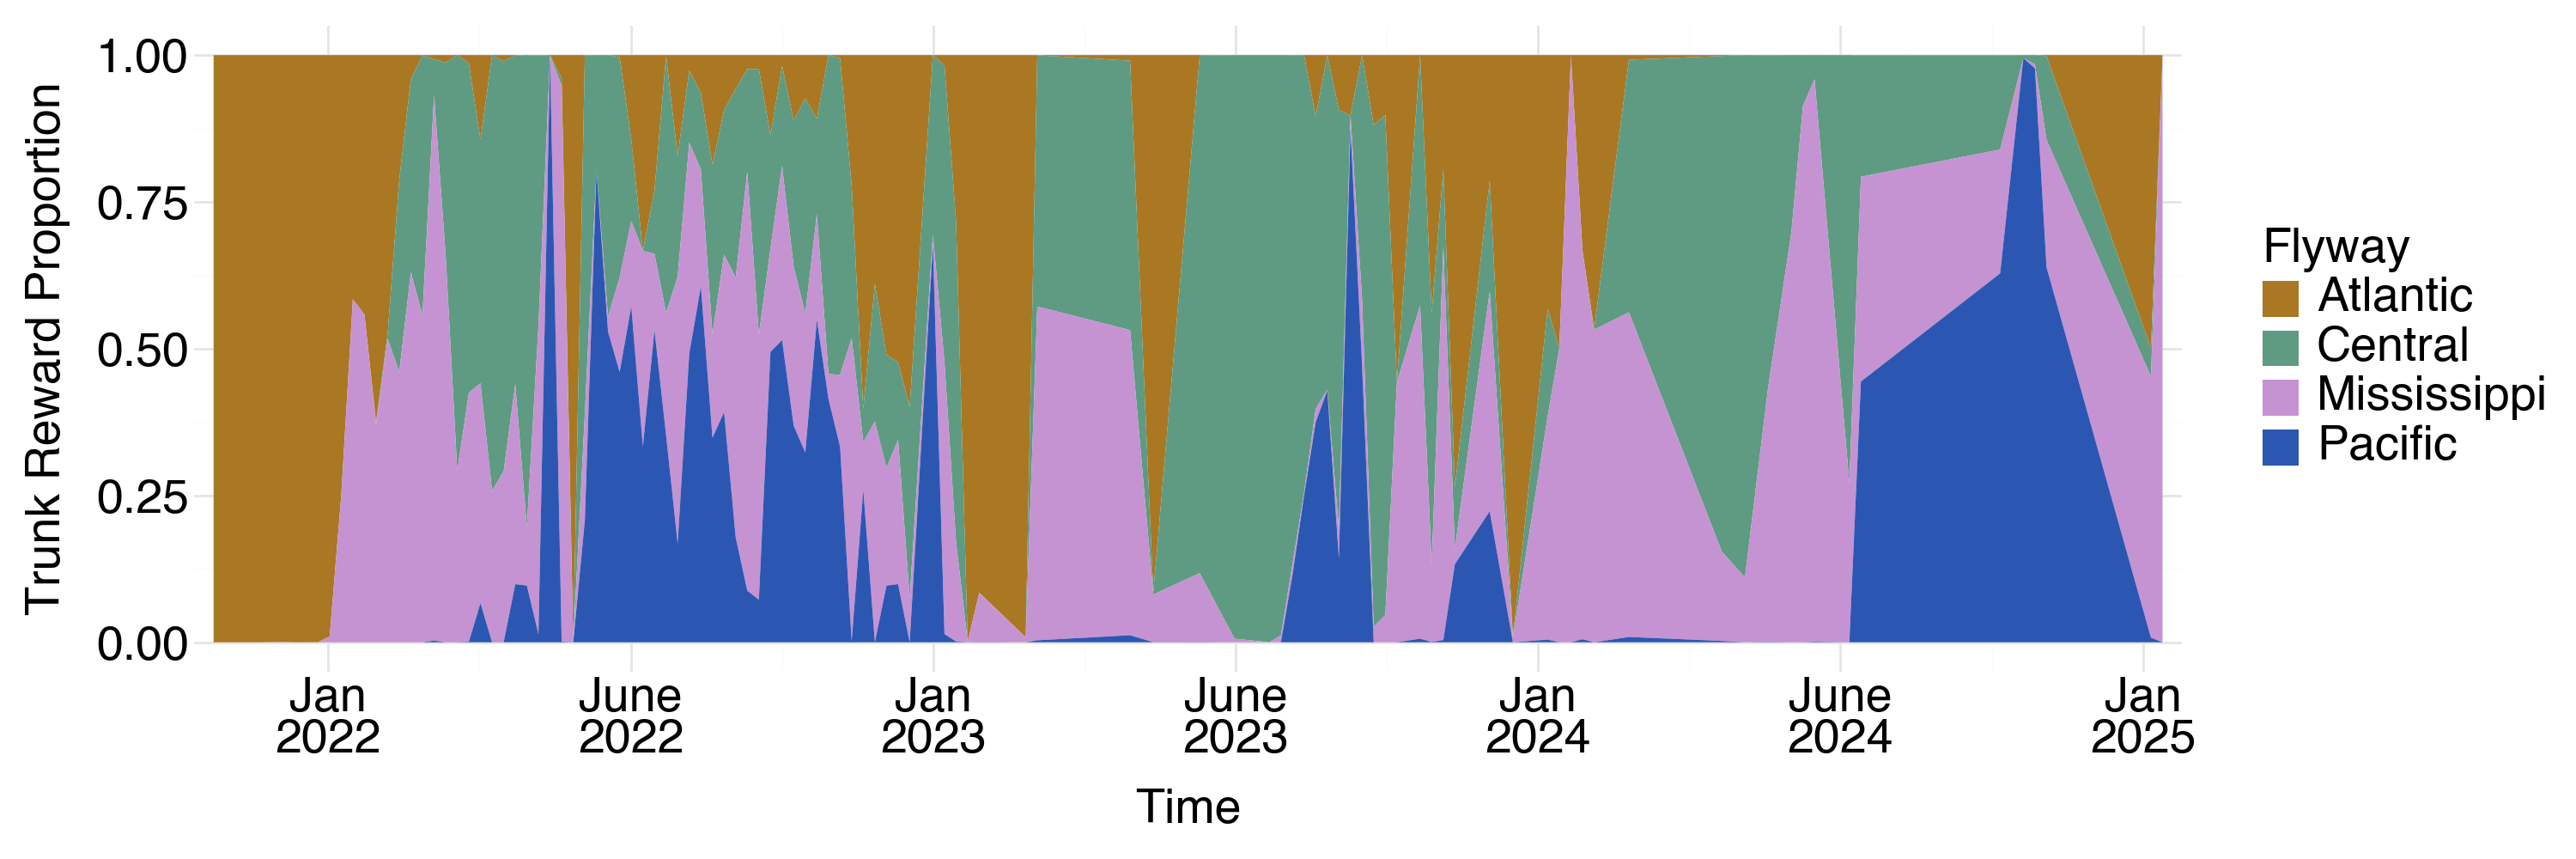

In [188]:
plt5A = (
    ggplot(weekly_host_rewards, aes(x = "week", y = "value", fill = "trait", group = "trait"))
    + geom_area()
    + scale_x_continuous(breaks = [2020.5, 2021, 2021.5, 2022, 2022.5, 2023, 2023.5, 2024, 2024.5, 2025, 2025.5, 2026],
                         # limits = [2020, 2026.25],
                         expand= [0.01, 0],
                         labels = ["June\n2020", "Jan\n2021", "June\n2021", "Jan\n2022", "June\n2022", "Jan\n2023", "June\n2023", "Jan\n2024", "June\n2024", "Jan\n2025", "June\n2025", "Jan\n2026"]
                        )
    + scale_fill_manual(values = host_colors_2, labels = host_labels_2)
    + labs(x = "Time", y = "Trunk Reward Proportion", fill = "Host")
    + theme_minimal()
    + theme(figure_size = (15, 5), axis_title_x = element_text(size = 20), axis_title_y = element_text(size = 20), text=element_text(size=20, color = "black"))
)

plt5B = (
    ggplot(weekly_flyway_rewards, aes(x = "week", y = "value", fill = "trait", group = "trait"))
    + geom_area()
    + scale_x_continuous(breaks = [2020.5, 2021, 2021.5, 2022, 2022.5, 2023, 2023.5, 2024, 2024.5, 2025, 2025.5, 2026],
                         # limits = [2020, 2026.25],
                         expand= [0.01, 0],
                         labels = ["June\n2020", "Jan\n2021", "June\n2021", "Jan\n2022", "June\n2022", "Jan\n2023", "June\n2023", "Jan\n2024", "June\n2024", "Jan\n2025", "June\n2025", "Jan\n2026"]
                        )
    + scale_fill_manual(values = flyway_colors, labels = flyway_labels)
    + labs(x = "Time", y = "Trunk Reward Proportion", fill = "Flyway")
    + theme_minimal()
    + theme(figure_size = (15, 5), axis_title_x = element_text(size = 20), axis_title_y = element_text(size = 20), text=element_text(size=20, color = "black"))
)

plt5A.show()
plt5B.show()

In [23]:
# Lastly, plot the bayes factors for each host and flyway

def load_bayes(PATH, labels):

    bayes = pd.read_csv(PATH, sep = "\t")

    bayes["label"] = bayes["FROM"].map(labels) + " - " + bayes["TO"].map(labels)

    return(bayes)

In [50]:
HOSTBAYES = "./analyses/main-intro_six-datasets_mjr/live-harvest/main-intro_liveharvest_host-bayes.txt"
FLYWAYBAYES = "./analyses/main-intro_six-datasets_mjr/live-harvest/main-intro_liveharvest_flyway-bayes.txt"

host_bayes = load_bayes(HOSTBAYES, host_labels)
flyway_bayes = load_bayes(FLYWAYBAYES, flyway_labels)

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10


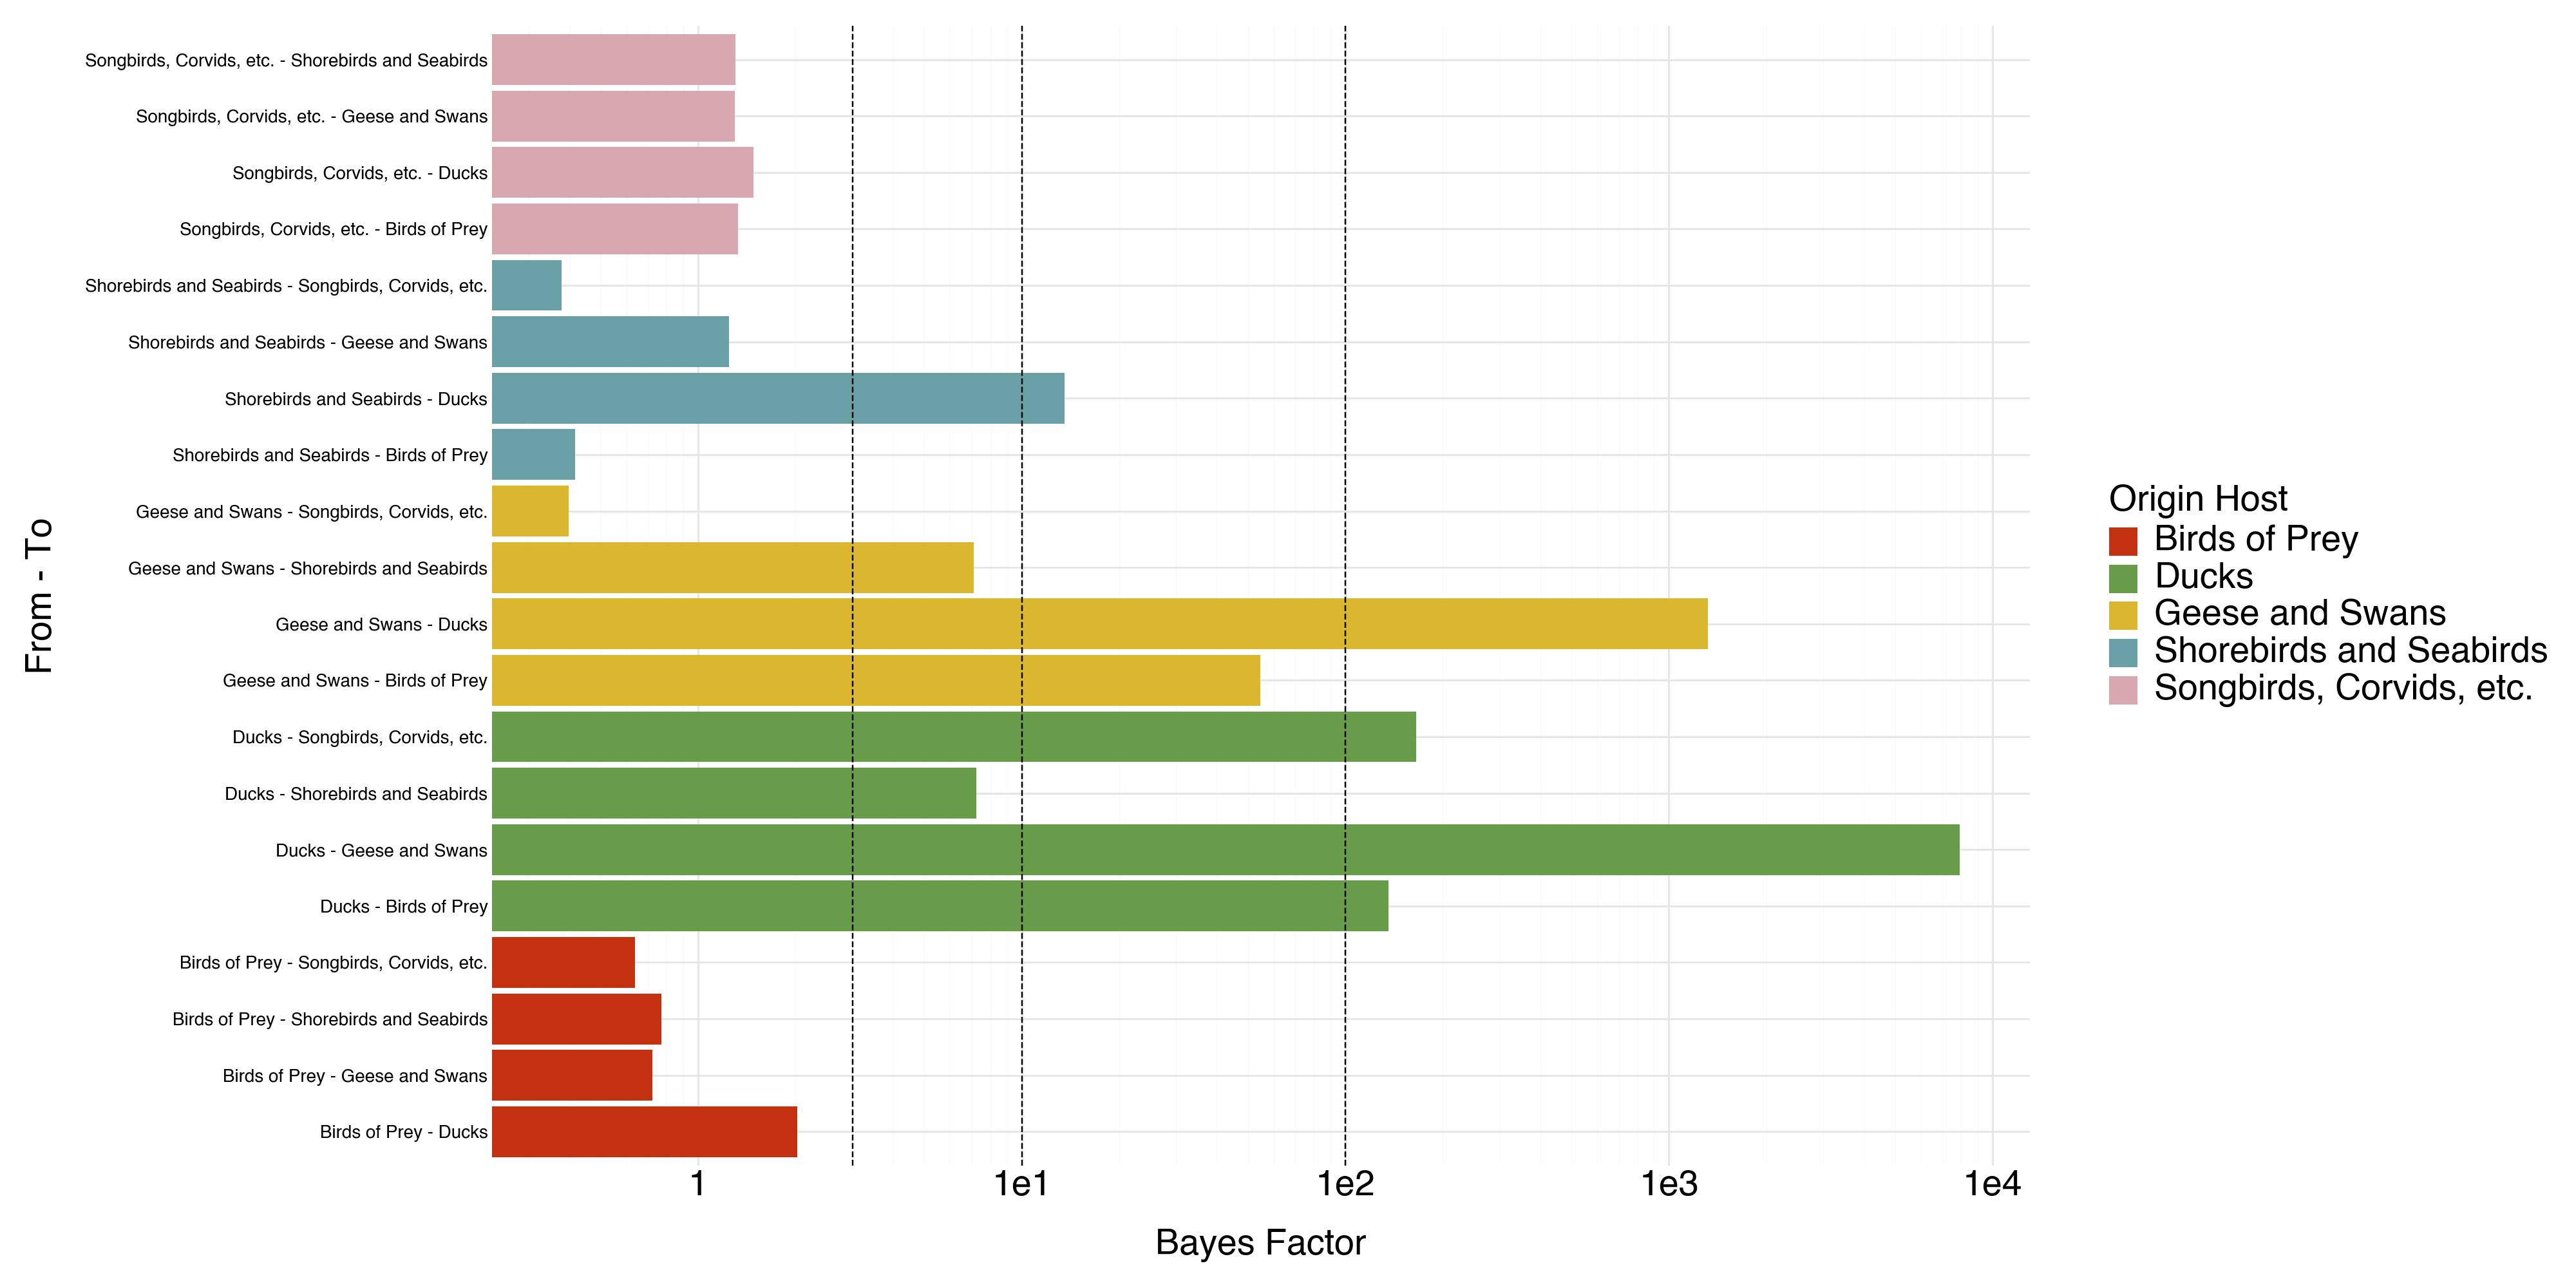

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10


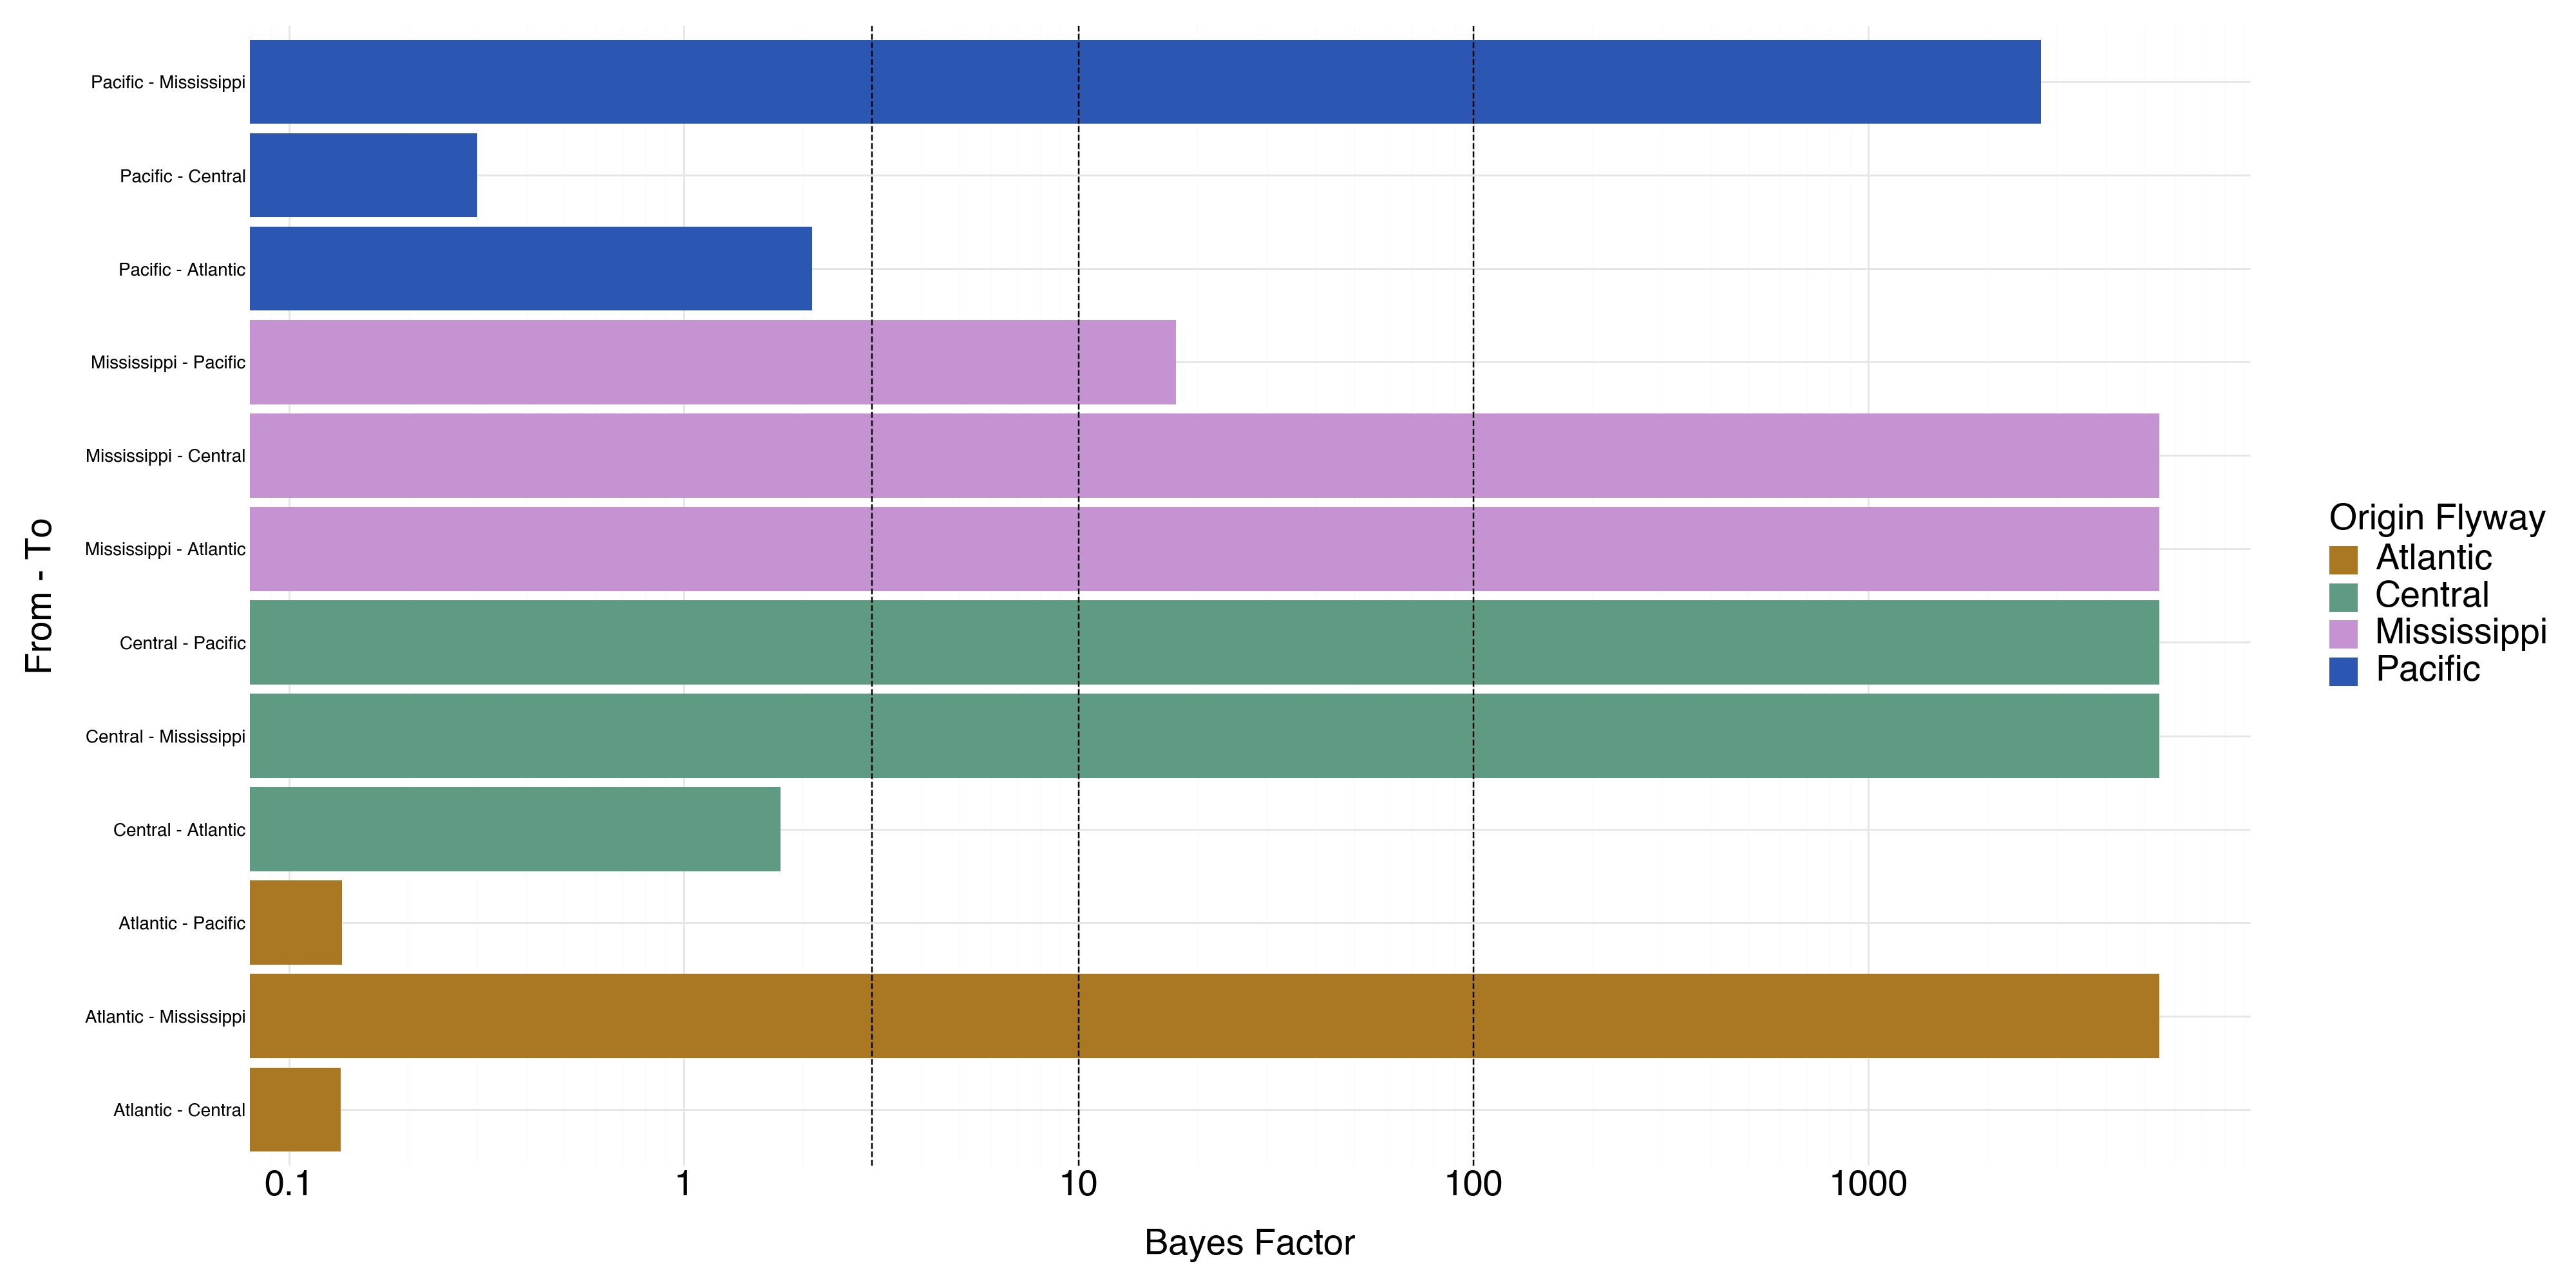

In [51]:
plt6A = (
    ggplot(host_bayes, aes(x = "label", y = "BAYES_FACTOR", fill = "FROM"))
    + geom_col(stat = "identity")
    + labs(x = "From - To", y = "Bayes Factor", fill = "Origin Host")
    + coord_flip()
    + scale_fill_manual(values = host_colors, labels = host_labels)
    + scale_y_log10()
    + geom_hline(yintercept = 3, linetype = "dashed", color = "black")
    + geom_hline(yintercept = 1e1, linetype = "dashed", color = "black")
    + geom_hline(yintercept = 1e2, linetype = "dashed", color = "black")
    + theme_minimal()
    + theme(figure_size = (20, 10), text=element_text(size=20, color = "black"), 
            axis_title_x = element_text(size = 20), axis_text_x = element_text(size = 20, color = "black"),
            axis_title_y = element_text(size = 20), axis_text_y = element_text(size = 10, color = "black"))
)

plt6B = (
    ggplot(flyway_bayes, aes(x = "label", y = "BAYES_FACTOR", fill = "FROM"))
    + geom_col(stat = "identity")
    + labs(x = "From - To", y = "Bayes Factor", fill = "Origin Flyway")
    + coord_flip()
    + scale_fill_manual(values = flyway_colors, labels = flyway_labels)
    + scale_y_log10()
    + geom_hline(yintercept = 3, linetype = "dashed", color = "black")
    + geom_hline(yintercept = 1e1, linetype = "dashed", color = "black")
    + geom_hline(yintercept = 1e2, linetype = "dashed", color = "black")    + theme_minimal()
    + theme(figure_size = (20, 10), text=element_text(size=20, color = "black"), 
            axis_title_x = element_text(size = 20), axis_text_x = element_text(size = 20, color = "black"),
            axis_title_y = element_text(size = 20), axis_text_y = element_text(size = 10, color = "black"))
)

plt6A.show()
plt6B.show()

In [52]:
# DIRECTORY = "equal-time-location"
# DIRECTORY = "equal-time-host-3000"
# DIRECTORY = "equal-time-host-1000"
# DIRECTORY = "proportional-time-host"
# DIRECTORY = "proportional-time-location"
DIRECTORY = "live-harvest"

In [190]:
plt1A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-net_{DIRECTORY}_host.png", format = "png", dpi = 750)
plt1A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-net_{DIRECTORY}_host.pdf", format = "pdf", dpi = 750)
plt1B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-net_{DIRECTORY}_flyway.png", format = "png", dpi = 750)
plt1B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-net_{DIRECTORY}_flyway.pdf", format = "pdf", dpi = 750)
plt2A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-origin-dest_{DIRECTORY}_host.png", format = "png", dpi = 750)
plt2A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-origin-dest_{DIRECTORY}_host.pdf", format = "pdf", dpi = 750)
plt2B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-origin-dest_{DIRECTORY}_flyway.png", format = "png", dpi = 750)
plt2B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-origin-dest_{DIRECTORY}_flyway.pdf", format = "pdf", dpi = 750)
plt3A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-overtime_{DIRECTORY}_host.png", format = "png", dpi = 750)
plt3A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-overtime_{DIRECTORY}_host.pdf", format = "pdf", dpi = 750)
plt3B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-overtime_{DIRECTORY}_flyway.png", format = "png", dpi = 750)
plt3B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mj-overtime_{DIRECTORY}_flyway.pdf", format = "pdf", dpi = 750)
plt4A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mr-total_{DIRECTORY}_host.png", format = "png", dpi = 750)
plt4A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mr-total_{DIRECTORY}_host.pdf", format = "pdf", dpi = 750)
plt4B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mr-total_{DIRECTORY}_flyway.png", format = "png", dpi = 750)
plt4B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mr-total_{DIRECTORY}_flyway.pdf", format = "pdf", dpi = 750)
plt5A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mr-weekly_{DIRECTORY}_host.png", format = "png", dpi = 750)
plt5A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mr-weekly_{DIRECTORY}_host.pdf", format = "pdf", dpi = 750)
plt5B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mr-weekly_{DIRECTORY}_flyway.png", format = "png", dpi = 750)
plt5B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/mr-weekly_{DIRECTORY}_flyway.pdf", format = "pdf", dpi = 750)
plt6A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/bayes-factor_{DIRECTORY}_host.png", format = "png", dpi = 750)
plt6A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/bayes-factor_{DIRECTORY}_host.pdf", format = "pdf", dpi = 750)
plt6B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/bayes-factor_{DIRECTORY}_flyway.png", format = "png", dpi = 750)
plt6B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/bayes-factor_{DIRECTORY}_flyway.pdf", format = "pdf", dpi = 750)

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./analyses/main-intro_six-datasets_mjr/live-harvest/mj-net_live-harvest_host.png
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./analyses/main-intro_six-datasets_mjr/live-harvest/mj-net_live-harvest_host.pdf
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./analyses/main-intro_six-datasets_mjr/live-ha